# Studio Proyek 3 — Fine-Tuning Transformer Pretrained untuk NLP (Revisi Lengkap)
**Mata kuliah:** Pembelajaran Mendalam (IF25-40401) · Institut Teknologi Sumatera  
**Tugas:** Klasifikasi sentimen teks Bahasa Indonesia (`positive` / `neutral` / `negative`) pada dataset **SmSA** (IndoNLU)  
**Kelompok:** 2 — Bayu Brigas Novaldi, Martino Kelvin, Rifka Priseilla

> **Panduan Penggunaan:** jalankan seluruh sel dari atas ke bawah (**Runtime → Run all**) dengan akselerator GPU aktif (**Runtime → Change runtime type → T4 GPU**).
> - `MODE = "uji"` (pada **Bagian 0**) menjalankan uji cepat (300 contoh, 1 epoch, 1 seed, ±3–5 menit) untuk memverifikasi seluruh alur tanpa error. Berkas keluaran diberi awalan `uji_`.
> - `MODE = "penuh"` menjalankan matriks eksperimen lengkap **3 backbone × 3 strategi × 3 seed = 27 run** sesuai rancangan.
> - **Checkpoint & Resume:** hasil setiap run langsung disimpan ke CSV (dan prediksi test disimpan ke `.npz`). Jika sesi Colab terputus, cukup jalankan ulang sel dari awal—run yang sudah selesai otomatis dilewati.

## 0. Persiapan Lingkungan & Reproduksibilitas
Impor seluruh pustaka utama sekali di awal, tentukan mode eksekusi (`"penuh"` atau `"uji"`), atur seed global (`set_seed(42)`), dan catat **ID sesi + tipe GPU**. Pencatatan sesi dan GPU memastikan **waktu latih dan waktu inferensi hanya dibandingkan dalam satu mesin/sesi yang sama**.

In [1]:
import os, gc, json, time, glob, hashlib, inspect, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
from torch.utils.data import DataLoader
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, get_linear_schedule_with_warmup, set_seed
)
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

MODE = "penuh"      # "penuh" = 27 run sesuai rancangan | "uji" = uji cepat (data kecil, 1 epoch, 1 seed)

# Folder keluaran. Disarankan mengaktifkan Google Drive agar hasil aman jika runtime Colab terputus.
RESULT_DIR = "."
try:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULT_DIR = "/content/drive/MyDrive/studio3"
except ImportError:                       # bukan Colab (mis. Kaggle): simpan di folder kerja
    RESULT_DIR = "."
os.makedirs(RESULT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    GPU = torch.cuda.get_device_name(0)
    VRAM_GB = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
else:
    GPU = "CPU"
    VRAM_GB = 0.0

# ID sesi: dibuat sekali per mesin virtual (disimpan di /tmp, hilang bila VM didaur ulang).
_f = "/tmp/studio3_sesi.txt"
if os.path.exists(_f):
    SESI = open(_f).read().strip()
else:
    SESI = datetime.now().strftime("%Y%m%d-%H%M%S")
    open(_f, "w").write(SESI)

set_seed(42)                                  # seed global awal; tiap run memanggil set_seed(seed)-nya sendiri
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

print(f"Mode     : {MODE} | Sesi: {SESI}")
print(f"Perangkat: {GPU} ({VRAM_GB:.1f} GB VRAM)" if DEVICE.type == "cuda" else f"Perangkat: {GPU}")
print(f"PyTorch  : {torch.__version__}")
if DEVICE.type != "cuda":
    print("PERINGATAN: GPU tidak aktif. Pelatihan di CPU terlalu lambat; aktifkan GPU T4 terlebih dahulu.")

Mounted at /content/drive
Mode     : penuh | Sesi: 20261120-081311
Perangkat: Tesla T4 (14.6 GB VRAM)
PyTorch  : 2.14.1+cu130


## 1. Muat Dataset SmSA
Sumber resmi: repositori GitHub **IndoNLU** (`indonlp/indonlu`, tugas `smsa_doc-sentiment-prosa`), dimuat langsung dari berkas TSV resmi (`train_preprocess.tsv`, `valid_preprocess.tsv`, `test_preprocess.tsv`) dan dikonversi ke `datasets.DatasetDict`.

- **Penting:** berkas `test_preprocess_masked_label.tsv` **tidak dipakai** karena label ujinya disamarkan (*masked*), sehingga seluruh metrik test menjadi tidak bermakna. Berkas `test_preprocess.tsv` berisi label uji asli. Sel di bawah memuat *pengaman* yang menghentikan notebook jika label uji tampak disamarkan.
- **Skema Label:** `0 = positive`, `1 = neutral`, `2 = negative`.
- Pengambilan langsung dari berkas TSV resmi menghindari ketergantungan pada skrip loader `datasets` versi lama sekaligus menjamin pembagian resmi (*official split*) tetap terjaga.

In [2]:
from datasets import Dataset, DatasetDict

pd.set_option("display.max_colwidth", 100)

# URL resmi dataset SmSA pada repositori GitHub IndoNLU
BASE_URL = "https://raw.githubusercontent.com/indonlp/indonlu/master/dataset/smsa_doc-sentiment-prosa"
train_url = f"{BASE_URL}/train_preprocess.tsv"
val_url   = f"{BASE_URL}/valid_preprocess.tsv"
test_url  = f"{BASE_URL}/test_preprocess.tsv"      # berlabel asli. JANGAN pakai ..._masked_label.tsv (label disamarkan)

# Muat file TSV
df_train = pd.read_csv(train_url, sep="\t", header=None, names=["text", "label"])
df_val   = pd.read_csv(val_url,   sep="\t", header=None, names=["text", "label"])
df_test  = pd.read_csv(test_url,  sep="\t", header=None, names=["text", "label"])

# Pemetaan label teks ke integer: 0 = positive, 1 = neutral, 2 = negative
LABELS = ["positive", "neutral", "negative"]
label_map = {name: idx for idx, name in enumerate(LABELS)}

for split_name, d_split in [("train", df_train), ("validation", df_val), ("test", df_test)]:
    assert not d_split["text"].isna().any(), f"Ditemukan teks kosong (NaN) pada split {split_name}"
    d_split["text"] = d_split["text"].astype(str)
    d_split["label"] = d_split["label"].map(label_map)
    assert not d_split["label"].isna().any(), f"Ditemukan label tidak dikenal pada split {split_name}"
    d_split["label"] = d_split["label"].astype(int)

# Pengaman: label uji harus asli (bukan label samaran), dan jumlahnya harus 500 (uji resmi SmSA)
dist_test = df_test["label"].value_counts(normalize=True)
assert df_test["label"].nunique() == 3, \
    f"Label uji tampak disamarkan (masked): hanya {df_test['label'].nunique()} kelas. Pastikan memakai test_preprocess.tsv"
assert dist_test.min() > 0.05, f"Sebaran kelas uji tidak wajar: {dist_test.round(3).to_dict()}"
assert len(df_test) == 500, f"Uji resmi SmSA seharusnya 500 kalimat, ditemukan {len(df_test)}"

# Rekonstruksi sebagai Hugging Face DatasetDict
ds = DatasetDict({
    "train": Dataset.from_pandas(df_train),
    "validation": Dataset.from_pandas(df_val),
    "test": Dataset.from_pandas(df_test)
})

print(ds)
print("Pemetaan Label:", dict(enumerate(LABELS)))
print("Sebaran kelas uji (harus 3 kelas, neutral minoritas):", {LABELS[k]: round(float(v), 3) for k, v in dist_test.sort_index().items()})

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 11000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1260
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 500
    })
})
Pemetaan Label: {0: 'positive', 1: 'neutral', 2: 'negative'}
Sebaran kelas uji (harus 3 kelas, neutral minoritas): {'positive': 0.416, 'neutral': 0.176, 'negative': 0.408}


## 2. Eksplorasi Data Train
Periksa distribusi kelas awal serta 20 contoh baris pertama pada split `train` untuk memahami karakteristik teks ulasan/komentar Bahasa Indonesia.

In [3]:
df = ds["train"].to_pandas()
df["label_name"] = df["label"].map(dict(enumerate(LABELS)))

print("Distribusi kelas (train asli):")
dist_awal = pd.DataFrame({
    "Jumlah": df["label_name"].value_counts(),
    "Proporsi (%)": df["label_name"].value_counts(normalize=True).mul(100).round(2)
})
display(dist_awal)

with pd.option_context("display.max_colwidth", None):   # tampilkan teks utuh
    display(df.head(20))

Distribusi kelas (train asli):


,Jumlah,Proporsi (%)
label_name,,
positive,6416,58.33
negative,3436,31.24
neutral,1148,10.44


,text,label,label_name
0,"warung ini dimiliki oleh pengusaha pabrik tahu yang sudah puluhan tahun terkenal membuat tahu putih di bandung . tahu berkualitas , dipadu keahlian memasak , dipadu kretivitas , jadilah warung yang menyajikan menu utama berbahan tahu , ditambah menu umum lain seperti ayam . semuanya selera indonesia . harga cukup terjangkau . jangan lewatkan tahu bletoka nya , tidak kalah dengan yang asli dari tegal !",0,positive
1,mohon ulama lurus dan k212 mmbri hujjah partai apa yang harus diwlh agar suara islam tidak pecah-pecah,1,neutral
2,"lokasi strategis di jalan sumatera bandung . tempat nya nyaman terutama sofa di lantai 2 . paella nya enak , sangat pas dimakan dengan minum bir dingin . appetiser nya juga enak-enak .",0,positive
3,betapa bahagia nya diri ini saat unboxing paket dan barang nya bagus ! menetapkan beli lagi !,0,positive
4,"duh . jadi mahasiswa jangan sombong dong . kasih kartu kuning segala . belajar dulu yang baik , tidak usahlah ikut-ikut politik . nanti sudah selesai kuliah nya mau ikut politik juga tidak telat . dasar mahasiswa .",2,negative
5,"makanan beragam , harga makanan di food stall akan ditambahkan 10 % lagi di kasir , suasana ramai dan perlu perhatian untuk mendapatkan parkir dan tempat duduk .",0,positive
6,pakai kartu kredit bca tidak untung malah rugi besar,2,negative
7,"tempat unik , bagus buat foto , makanan enak , pegawai ramah , bersih dan luas , wifi kencang . harga standar dan sesuai dengan tempat nya . ada menu masakan makanan barat dan indonesia . menu favorit lychee mojito dan spagheti",0,positive
8,"saya bersama keluarga baru saja menikmati pengalaman kuliner yang menyenangkan di rm sari sunda di jalan . setiabudhi , bandung . tapi , karena tidak ada hubungan untuk rm sari sunda di jalan . setiabudhi , maka saya tuliskan di sini . jadi , maaf jika rekan-rekan pembaca ada yang bingung . beberapa hal yang saya suka dari restoran ini adalah bahwa pelayanan restoran ini terbilang cepat .",0,positive
9,bersyukur,0,positive


## 3. Cek Duplikasi Data Train
Teks yang muncul lebih dari sekali dikelompokkan, lalu dibagi menjadi dua kategori:

- **Duplikat murni**: teks dan label identik → disisakan **1 salinan**, sisanya dibuang agar tidak membobotkan contoh tertentu secara berlebih.
- **Label bertentangan**: teks identik tetapi memiliki label berbeda → **seluruh kelompok dibuang**, karena label kebenaran dasar (*ground truth*) bersifat ambigu.


RINGKASAN DUPLIKASI DATA TRAIN
Total baris train                 : 11,000
Kelompok teks muncul > 1 kali     : 58
Total baris dalam kelompok        : 125
Baris kelebihan (salinan)         : 67  (125 baris - 58 kelompok)
  Duplikat murni                  : 58 kelompok
  Label bertentangan              : 0 kelompok

Sebaran ukuran kelompok:
  Muncul 2x : 52 kelompok (52 x 2 = 104 baris)
  Muncul 3x : 3 kelompok (3 x 3 = 9 baris)
  Muncul 4x : 3 kelompok (3 x 4 = 12 baris)

DAMPAK PEMBERSIHAN (duplikasi di dalam train)
Baris awal                        : 11,000
- Salinan duplikat murni dibuang  : 67
- Baris label bertentangan dibuang: 0
Baris akhir                       : 10,933


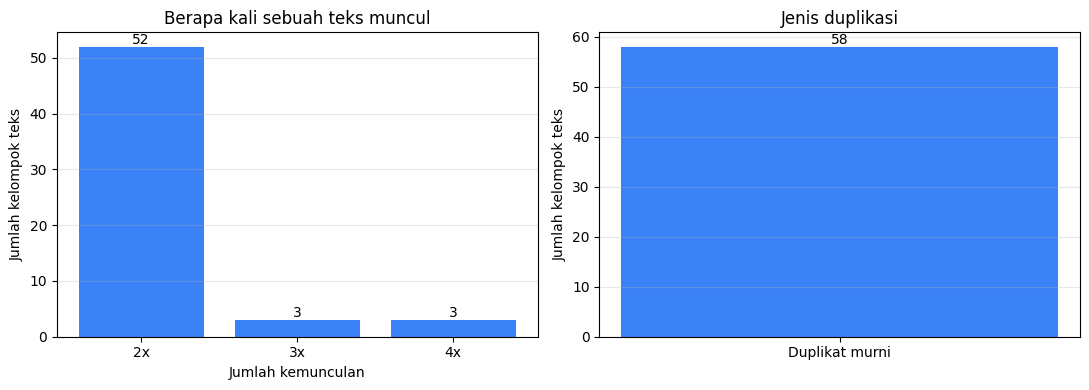


CONTOH: 5 kelompok duplikat murni terbanyak


,text,jumlah,label_muncul
25,jangan pernah kecewa dengan apa yang diberikan oleh tuhan,4,positive
30,kesal,4,negative
52,tidak kesal,4,positive
5,berantakan,3,negative
7,berkesempatan menikmati santap pagi dikarenakan sedang menginap di hotel padma bandung . sebagai...,3,positive


CONTOH: kelompok berlabel bertentangan
Tidak ada.


In [4]:
# Kelompokkan teks yang muncul > 1 kali
g = (df.groupby("text")
       .agg(jumlah=("label", "size"), n_label=("label", "nunique"),
            label_muncul=("label_name", lambda s: ", ".join(sorted(set(s)))))
       .query("jumlah > 1").reset_index())
g["jenis"] = g["n_label"].map(lambda n: "Duplikat murni" if n == 1 else "Label bertentangan")
murni, konflik = g[g["n_label"] == 1], g[g["n_label"] > 1]

n_baris, n_kelompok = int(g["jumlah"].sum()), len(g)
hapus_murni = int((murni["jumlah"] - 1).sum())   # sisakan 1 salinan per kelompok
hapus_konflik = int(konflik["jumlah"].sum())     # buang seluruh kelompok

def judul(teks):
    print(f"\n{'=' * 55}\n{teks}\n{'=' * 55}")

# ---------- Ringkasan ----------
judul("RINGKASAN DUPLIKASI DATA TRAIN")
print(f"Total baris train                 : {len(df):,}")
print(f"Kelompok teks muncul > 1 kali     : {n_kelompok}")
print(f"Total baris dalam kelompok        : {n_baris}")
print(f"Baris kelebihan (salinan)         : {n_baris - n_kelompok}  ({n_baris} baris - {n_kelompok} kelompok)")
print(f"  Duplikat murni                  : {len(murni)} kelompok")
print(f"  Label bertentangan              : {len(konflik)} kelompok")
print("\nSebaran ukuran kelompok:")
for u, n in g["jumlah"].value_counts().sort_index().items():
    print(f"  Muncul {u}x : {n} kelompok ({n} x {u} = {n * u} baris)")

# ---------- Dampak pembersihan ----------
judul("DAMPAK PEMBERSIHAN (duplikasi di dalam train)")
print(f"Baris awal                        : {len(df):,}")
print(f"- Salinan duplikat murni dibuang  : {hapus_murni}")
print(f"- Baris label bertentangan dibuang: {hapus_konflik}")
print(f"Baris akhir                       : {len(df) - hapus_murni - hapus_konflik:,}")

# ---------- Grafik ----------
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
panel = [
    (ax[0], g["jumlah"].value_counts().sort_index(), "Berapa kali sebuah teks muncul", "Jumlah kemunculan"),
    (ax[1], g["jenis"].value_counts(), "Jenis duplikasi", "")
]
for a, data, judul_g, xlabel in panel:
    bars = a.bar([f"{i}x" if str(i).isdigit() else i for i in data.index], data.values, color="#3b82f6")
    a.bar_label(bars)
    a.set(title=judul_g, xlabel=xlabel, ylabel="Jumlah kelompok teks")
    a.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ---------- Contoh ----------
print("\nCONTOH: 5 kelompok duplikat murni terbanyak")
display(murni.nlargest(5, "jumlah")[["text", "jumlah", "label_muncul"]])

print("CONTOH: kelompok berlabel bertentangan")
if len(konflik):
    display(df[df["text"].isin(konflik["text"])].sort_values("text")[["text", "label_name"]])
else:
    print("Tidak ada.")

### Temuan Duplikasi Data Train
- Terdapat **58 teks** yang muncul lebih dari sekali (52 muncul 2×, 3 muncul 3×, 3 muncul 4×) dengan total **125 baris**.
- Dari 125 baris tersebut, **67 baris** merupakan salinan berlebih yang dibuang dan **58 baris** disisakan (1 salinan unik per teks).
- Seluruhnya merupakan **duplikat murni** (tidak ditemukan konflik label).
- Jumlah data latih setelah deduplikasi: 11.000 − 67 = **10.933 baris**.
- Pemeriksaan kebocoran data (*data leakage*) lintas split dilakukan pada bagian berikutnya.

## 4. Pembersihan Data & Audit Kebocoran Lintas Split (Train, Validation, Test)
Sesuai protokol eksperimen, SmSA menggunakan **pembagian resmi** dengan aturan pembersihan berikut:

| Split | Perlakuan | Alasan Metodologis |
|---|---|---|
| **Train** | Buang salinan duplikat murni (sisakan 1) dan seluruh kelompok berlabel bertentangan | Mencegah bias bobot sampel berulang dan ambiguitas label |
| **Validation** | **Buang teks yang juga muncul di train asli** serta duplikat internal validation | Menghilangkan kebocoran data (*data leakage*) sehingga skor validasi benar-benar mengukur generalisasi |
| **Test** | **Dipakai utuh** (pembagian resmi); tumpang tindih dengan train/validation hanya diaudit dan dilaporkan | Menjaga komparabilitas benchmark resmi IndoNLU |

Teks validasi dibandingkan terhadap **train asli** (bukan hanya `train_bersih`), sehingga teks berlabel bertentangan yang dibuang dari train pun tidak bocor melalui validasi.

In [5]:
# ---------- Train: duplikat murni disisakan 1, kelompok berlabel bertentangan dibuang ----------
train_asli = ds["train"].to_pandas()
train_asli["label_name"] = train_asli["label"].map(dict(enumerate(LABELS)))

teks_konflik = train_asli.groupby("text")["label"].nunique().loc[lambda s: s > 1].index
train_bersih = (train_asli[~train_asli["text"].isin(teks_konflik)]
                .drop_duplicates("text").reset_index(drop=True))

# ---------- Validation: buang teks yang bocor dari train asli + duplikat internal ----------
teks_train = set(train_asli["text"])
val_asli = ds["validation"].to_pandas()
bocor_val_train = val_asli["text"].isin(teks_train)
val_tanpa_bocor = val_asli[~bocor_val_train].copy()
n_dup_val = int(val_tanpa_bocor.duplicated("text").sum())
val_bersih = val_tanpa_bocor.drop_duplicates("text").reset_index(drop=True)
val_bersih["label_name"] = val_bersih["label"].map(dict(enumerate(LABELS)))

# ---------- Test: dipakai utuh, audit tumpang tindih dengan train, validation, & internal ----------
test_df = ds["test"].to_pandas()
test_df["label_name"] = test_df["label"].map(dict(enumerate(LABELS)))
n_test_train = int(test_df["text"].isin(teks_train).sum())
n_test_val   = int(test_df["text"].isin(set(val_bersih["text"])).sum())
n_test_dup   = int(test_df.duplicated("text").sum())

print(f"Train      : {len(train_asli):,} -> {len(train_bersih):,}  (dibuang {len(train_asli) - len(train_bersih)} salinan duplikat)")
print(f"Validation : {len(val_asli):,} -> {len(val_bersih):,}  (dibuang {int(bocor_val_train.sum())} bocor dari train, {n_dup_val} duplikat internal)")
print(f"Test       : {len(test_df):,} (utuh; {n_test_train} tumpang tindih dgn train, {n_test_val} dgn val, {n_test_dup} duplikat internal)")

print("\nDistribusi kelas setelah pembersihan (jumlah dan proporsi %):")
ringkasan_split = pd.DataFrame({
    "Train (n)": train_bersih["label_name"].value_counts(),
    "Train (%)": train_bersih["label_name"].value_counts(normalize=True).mul(100).round(1),
    "Val (n)": val_bersih["label_name"].value_counts(),
    "Val (%)": val_bersih["label_name"].value_counts(normalize=True).mul(100).round(1),
    "Test (n)": test_df["label_name"].value_counts(),
    "Test (%)": test_df["label_name"].value_counts(normalize=True).mul(100).round(1),
})
display(ringkasan_split)

# Ketentuan studi kasus: validasi >= 500 sampel; uji = seluruh uji resmi SmSA (500 kalimat) dengan label asli
assert len(val_bersih) >= 500, f"Validasi hanya {len(val_bersih)} sampel (minimal 500)"
assert len(test_df) == 500, f"Uji resmi SmSA seharusnya 500 kalimat, ditemukan {len(test_df)}"
assert test_df["label"].nunique() == 3, "Label uji tampak disamarkan (masked)"


Train      : 11,000 -> 10,933  (dibuang 67 salinan duplikat)
Validation : 1,260 -> 1,246  (dibuang 14 bocor dari train, 0 duplikat internal)
Test       : 500 (utuh; 0 tumpang tindih dgn train, 0 dgn val, 0 duplikat internal)

Distribusi kelas setelah pembersihan (jumlah dan proporsi %):


,Train (n),Train (%),Val (n),Val (%),Test (n),Test (%)
label_name,,,,,,
positive,6383,58.4,728,58.4,208,41.6
negative,3412,31.2,389,31.2,204,40.8
neutral,1138,10.4,129,10.4,88,17.6


**Temuan Pembersihan & Audit** (angka persis dicetak oleh sel di atas):
- Train dan validation setelah pembersihan memiliki proporsi kelas yang konsisten: `positive` (±58%), `negative` (±31%), dan kelas minoritas `neutral` (±10%).
- **Sebaran kelas test berbeda dari train/validation** (sesuai catatan studi kasus: sebaran uji berbeda dari latih); bandingkan kolom `Test (%)` pada tabel di atas. Karena itu **F1 makro** dan **F1 kelas `neutral`** dilaporkan di samping akurasi, dan hasil test tidak boleh dibaca sebagai estimasi sebaran latih.
- Distribusi kelas tidak seimbang (*imbalanced*; `neutral` hanya ~10% pada train), sehingga **F1 makro** ditetapkan sebagai metrik utama di samping **akurasi**, dan **F1 khusus kelas `neutral`** turut dilacak pada setiap eksperimen.
- Audit tumpang tindih pada test dilaporkan apa adanya (test dipakai utuh); jumlahnya dicetak di atas.


# Rancangan Eksperimen (Soal 1)

## 1. Dataset & Strategi Pengambilan Sampel
- **Dataset:** **SmSA (IndoNLU)** — klasifikasi sentimen 3 kelas (`positive` / `neutral` / `negative`) menggunakan pembagian resmi setelah pembersihan.
- **Subset Latih:** `5.000` contoh (stratified, diambil **sekali** dengan `subset_seed=42` setelah deduplikasi, sehingga seluruh 27 run melihat data latih yang persis sama). Validation = pembagian resmi yang sudah dibersihkan dari kebocoran (≥ 500 contoh, dipakai **hanya** untuk memilih epoch terbaik); test = seluruh uji resmi **berlabel asli** (500 kalimat, berkas `test_preprocess.tsv`), digunakan utuh dan **disentuh sekali per run**. Ukuran ini sesuai ketentuan studi kasus (train 3.000–6.000, validasi ≥ 500, uji 500).
- **Alasan:** Menjalankan 27 run pada 10.933 contoh penuh memakan waktu ±2× lebih lama dan berisiko melebihi batas sesi GPU gratis Colab. Pengambilan *stratified* 5.000 contoh menjaga proporsi kelas minoritas `neutral` tetap identik dengan dataset asli sekaligus memastikan seluruh matriks selesai dengan nyaman. *(Ketentuan studi kasus membatasi data latih maksimal 6.000 contoh, sehingga `n_train` dikunci pada rentang 3.000–6.000.)*

## 2. Matriks Eksperimen (3 Backbone × 3 Strategi × 3 Seed = 27 Run)
| Backbone | Model ID HuggingFace | Full Fine-Tuning | Partial Freezing | Linear Probing |
|---|---|---|---|---|
| **BERT** | `bert-base-multilingual-cased` | ✓ (100% param) | ✓ (Embedding + 6/12 lapis awal beku) | ✓ (Hanya head dilatih) |
| **DistilBERT** | `distilbert-base-multilingual-cased` | ✓ (100% param) | ✓ (Embedding + 3/6 lapis awal beku) | ✓ (Hanya head dilatih) |
| **IndoBERT** | `indobenchmark/indobert-base-p1` | ✓ (100% param) | ✓ (Embedding + 6/12 lapis awal beku) | ✓ (Hanya head dilatih) |

- Head klasifikasi diganti baru (`num_labels=3`) pada seluruh run.
- Catatan arsitektur: **DistilBERT** memiliki lapisan tambahan `pre_classifier` sebelum `classifier` dan tidak menggunakan `pooler` maupun `token_type_ids`, sedangkan **BERT** dan **IndoBERT** menggunakan `pooler` + `classifier`. Dalam definisi strategi *linear probing* dan *partial freezing*, seluruh lapisan di luar `base_model` (yakni `classifier`, serta `pre_classifier` pada DistilBERT) selalu ikut dilatih.

## 3. Variabel Terkendali
| Variabel | Nilai Terkunci |
|---|---|
| `max_length` | `128` (pemotongan saja; *dynamic padding* per batch via `DataCollatorWithPadding`) |
| Batch size | `32` (latih) · `64` (validasi, uji, & pengukuran inferensi) |
| Epoch | `3` |
| Seed | `42, 43, 44` (untuk tiap run) · `subset_seed = 42` (untuk pengambilan subset latih) |
| Learning rate | Full: `3e-5` · Partial: `3e-5` · Linear Probing: `2e-3` |
| Optimizer & Scheduler | AdamW, `weight_decay = 0.01` (tanpa decay pada `bias` dan `LayerNorm`), linear warmup `10%` lalu linear decay, mixed precision `fp16`, gradient clipping `1.0` |
| Seleksi Epoch & Pelaporan | Validation **hanya** dipakai memilih **epoch terbaik** (F1 makro validasi tertinggi di antara 3 epoch); bobot epoch itu dipulihkan, lalu test dievaluasi **sekali** per run; hasil dilaporkan sebagai **rata-rata ± simpangan baku sampel (`ddof=1`)** antar 3 seed |
| Metrik | Akurasi, F1 makro, F1 per kelas (termasuk kelas minoritas `neutral`), waktu latih (detik), waktu inferensi (`ms/kalimat`), parameter total & terlatih, memori puncak GPU (MB) |

## 4. Hipotesis Penelitian
- **H1 (Keunggulan Domain Bahasa — Soal 2):** Pada protokol dan strategi yang identik (*full fine-tuning*), **IndoBERT** mencapai F1 makro tertinggi dibandingkan BERT multibahasa dan DistilBERT multibahasa karena prapelatihannya menggunakan korpus Bahasa Indonesia secara khusus.
- **H2 (Efisiensi Komputasi — Soal 2):** **DistilBERT** memangkas jumlah parameter, waktu latih, dan waktu inferensi secara signifikan dibandingkan BERT multibahasa dengan penurunan F1 makro **≤ 3 poin (0,03)**.
- **H3 (Trade-off Strategi Adaptasi — Soal 3):** Urutan F1 makro mengikuti **Full Fine-Tuning ≥ Partial Freezing > Linear Probing**, sedangkan urutan kebutuhan waktu latih dan memori puncak GPU mengikuti arah sebaliknya (**Full > Partial > Probing**).

## 5. Alasan Desain
- **Protokol identik antar backbone** (hiperparameter, seed, subset latih, dan jumlah epoch sama) agar perbandingan backbone adil; perbedaan hasil hanya berasal dari backbone atau strategi.
- **Learning rate dibedakan per strategi:** linear probing hanya melatih head sehingga membutuhkan learning rate jauh lebih besar (2e-3) daripada full/partial (3e-5).
- **3 seed per kombinasi** dan pelaporan **rata-rata ± simpangan baku sampel**, bukan nilai terbaik dari satu kali coba.
- **Model English-only tidak dipakai** karena dataset berbahasa Indonesia (menghindari faktor bahasa yang mencampuri perbandingan backbone).
- **Validation hanya untuk memilih epoch terbaik; test disentuh sekali per run** pada bobot epoch terpilih, sehingga skor test bebas bias seleksi. Waktu inferensi diukur pada data validasi agar test tidak tersentuh berulang.
- **Waktu latih dan inferensi dibandingkan hanya dalam satu sesi/GPU yang sama** (ID sesi dan nama GPU dicatat pada setiap baris hasil).
- **Input identik tanpa `token_type_ids`** untuk semua backbone, karena DistilBERT tidak menerimanya; untuk BERT/IndoBERT, menghilangkannya setara dengan nilai bawaan (semua 0) pada tugas satu kalimat.
- **Label uji asli (`test_preprocess.tsv`)**, bukan berkas dengan label disamarkan; ada pengaman otomatis dan pemeriksaan kewajaran skor setelah rekap.

## 6. Pembanding yang Sah
Tidak ada angka "yang benar". Skor Transformer dibandingkan dengan: (1) **baseline TF-IDF + Logistic Regression** yang dilatih di notebook ini pada data latih penuh (acuan studi kasus: F1 makro ≈ 0,73), (2) **tebakan acak** (≈ 0,33 untuk 3 kelas), dan (3) **simpangan baku antar-seed**. Selisih yang lebih kecil daripada simpangan antar-seed dianggap **belum bermakna**.


In [6]:
CONFIG = dict(
    dataset="SmSA (IndoNLU), pembagian resmi, setelah pembersihan",
    n_train=5000,                 # subset train (stratified); ketentuan studi kasus: 3.000-6.000
    subset_seed=42,               # seed pengambilan subset (tetap, terpisah dari seed run)
    max_length=128,
    batch_size=32,
    eval_batch_size=64,
    epochs=3,
    seeds=[42, 43, 44],           # sama untuk semua run
    lr={"full": 3e-5, "partial": 3e-5, "probing": 2e-3},
    weight_decay=0.01, warmup_ratio=0.1, max_grad_norm=1.0, fp16=True,
    pilih_epoch="F1 makro validasi tertinggi (validasi hanya dipakai untuk ini)",
    sumber_test="test_preprocess.tsv (label asli, bukan masked)",   # ikut menentukan KODE konfigurasi
)
BACKBONES = {
    "BERT": "bert-base-multilingual-cased",
    "DistilBERT": "distilbert-base-multilingual-cased",
    "IndoBERT": "indobenchmark/indobert-base-p1",
}
STRATEGIES = ["full", "partial", "probing"]

# Matriks backbone x strategi
matriks = pd.DataFrame("✓", index=list(BACKBONES), columns=STRATEGIES)
display(matriks)

n_seed = len(CONFIG["seeds"])
n_run = len(BACKBONES) * len(STRATEGIES) * n_seed
print(f"Total run: {len(BACKBONES)} backbone × {len(STRATEGIES)} strategi × {n_seed} seed = {n_run} run")

# Pengaman: rancangan tidak boleh kosong, seed minimal 3, LR dan ukuran data sesuai spesifikasi/studi kasus
assert all(v is not None for v in CONFIG.values()), "Rancangan belum lengkap"
assert 3000 <= CONFIG["n_train"] <= 6000, "Ukuran data latih harus 3.000-6.000 (studi kasus)"
assert n_seed >= 3, "Minimal 3 seed"
assert all(2e-5 <= CONFIG["lr"][k] <= 5e-5 for k in ("full", "partial")), "LR full/partial di luar 2e-5..5e-5"
assert 1e-3 <= CONFIG["lr"]["probing"] <= 5e-3, "LR probing di luar 1e-3..5e-3"
assert len(BACKBONES) >= 3 and len(STRATEGIES) >= 2, "Minimal 3 backbone dan 2 strategi"

# Konfigurasi aktif: mode uji mengecilkan skala tanpa mengubah CONFIG resmi
CFG = CONFIG if MODE == "penuh" else {**CONFIG, "n_train": 300, "epochs": 1, "seeds": [CONFIG["seeds"][0]]}

# Kode hash konfigurasi: menjamin hasil konfigurasi berbeda tidak tercampur
KODE = hashlib.md5(json.dumps({"cfg": CFG, "backbones": BACKBONES, "strategi": STRATEGIES},
                              sort_keys=True).encode()).hexdigest()[:6]
PREFIX = "" if MODE == "penuh" else "uji_"
FILE_HASIL = os.path.join(RESULT_DIR, f"{PREFIX}hasil_smsa_{KODE}.csv")
FILE_REKAP = os.path.join(RESULT_DIR, f"{PREFIX}rekap_agregat_smsa_{KODE}.csv")
FILE_BENCH = os.path.join(RESULT_DIR, f"{PREFIX}benchmark_inferensi_smsa_{KODE}.csv")
PRED_DIR   = os.path.join(RESULT_DIR, f"{PREFIX}preds_{KODE}")
os.makedirs(PRED_DIR, exist_ok=True)

RANCANGAN_OK = True   # diperiksa oleh sel eksekusi sebelum berjalan
print(f"\nKode konfigurasi : {KODE}")
print(f"Berkas hasil     : {os.path.basename(FILE_HASIL)}")
print(f"Berkas rekap     : {os.path.basename(FILE_REKAP)}")
print(f"Folder prediksi  : {os.path.basename(PRED_DIR)}/")

,full,partial,probing
BERT,✓,✓,✓
DistilBERT,✓,✓,✓
IndoBERT,✓,✓,✓


Total run: 3 backbone × 3 strategi × 3 seed = 27 run

Kode konfigurasi : 5579c1
Berkas hasil     : hasil_smsa_5579c1.csv
Berkas rekap     : rekap_agregat_smsa_5579c1.csv
Folder prediksi  : preds_5579c1/


## Subset Train & Pemeriksaan Panjang Token
Subset latih dibuat **sekali** secara *stratified* (`subset_seed=42`) dan digunakan bersama oleh seluruh run. Selanjutnya distribusi panjang token diperiksa pada ketiga tokenizer untuk memastikan `max_length = 128` tidak memotong informasi penting.

In [7]:
# ---------- Subset train (stratified), tetap untuk semua run ----------
if CFG["n_train"] is not None and CFG["n_train"] < len(train_bersih):
    train_sub, _ = train_test_split(
        train_bersih, train_size=CFG["n_train"],
        stratify=train_bersih["label"], random_state=CFG["subset_seed"]
    )
else:
    train_sub = train_bersih
train_sub = train_sub.reset_index(drop=True)

print(f"Subset train: {len(train_sub):,} dari {len(train_bersih):,} baris bersih")
display(pd.DataFrame({
    "Train bersih (%)": train_bersih["label_name"].value_counts(normalize=True).mul(100).round(1),
    "Subset (%)": train_sub["label_name"].value_counts(normalize=True).mul(100).round(1),
    "Subset (n)": train_sub["label_name"].value_counts()
}))

# ---------- Panjang token per backbone ----------
ML = CFG["max_length"]
tok_stats = []
for nama, model_id in BACKBONES.items():
    tok = AutoTokenizer.from_pretrained(model_id)
    panjang = np.array([len(x) for x in tok(train_sub["text"].tolist())["input_ids"]])
    tok_stats.append({
        "Backbone": nama,
        "Ukuran Vocab": f"{len(tok):,}",
        "Rata-rata Token": round(float(panjang.mean()), 1),
        "Persentil-95": int(np.percentile(panjang, 95)),
        "Maksimum": int(panjang.max()),
        f"Terpotong (>{ML})": f"{(panjang > ML).mean():.2%}"
    })
display(pd.DataFrame(tok_stats).set_index("Backbone"))

Subset train: 5,000 dari 10,933 baris bersih


,Train bersih (%),Subset (%),Subset (n)
label_name,,,
positive,58.4,58.4,2919
negative,31.2,31.2,1560
neutral,10.4,10.4,521


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

,Ukuran Vocab,Rata-rata Token,Persentil-95,Maksimum,Terpotong (>128)
Backbone,,,,,
BERT,"119,547",50.0,104,176,0.18%
DistilBERT,"119,547",50.0,104,176,0.18%
IndoBERT,"30,521",37.8,79,132,0.02%


**Interpretasi Panjang Token:**
- Rata-rata panjang urutan berada pada rentang **38–50 token** dan persentil ke-95 berada di bawah **105 token**, sehingga `max_length = 128` mencakup >99,8% teks tanpa pemotongan.
- Tokenizer **IndoBERT** (kosakata khusus Bahasa Indonesia ±30,5 ribu) menghasilkan urutan token yang lebih ringkas dibandingkan tokenizer multibahasa (±119,5 ribu), sehingga mengurangi beban komputasi lapisan *self-attention* ($O(L^2)$).

## Baseline Pembanding: TF-IDF + Logistic Regression
Studi kasus menetapkan pembanding yang sah: **baseline TF-IDF notebook sendiri** (acuan F1 makro ≈ 0,73 pada data latih penuh), **tebakan acak**, dan simpangan antar-seed. Baseline dilatih sekali di sini (tanpa GPU), dievaluasi pada seluruh uji resmi, dan dipakai nanti untuk memeriksa kewajaran skor Transformer. Baris kedua memakai subset 5.000 yang sama dengan Transformer sebagai perbandingan apple-to-apple.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline


def _skor(y, p):
    return accuracy_score(y, p), f1_score(y, p, average="macro", zero_division=0)


hasil_baseline = []
for ket, dtrain in [("TF-IDF + LogReg, train bersih penuh", train_bersih),
                    ("TF-IDF + LogReg, subset Transformer", train_sub)]:
    t0 = time.perf_counter()
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         LogisticRegression(max_iter=2000, C=5.0, random_state=42))
    pipe.fit(dtrain["text"], dtrain["label"])
    waktu = time.perf_counter() - t0
    acc, f1 = _skor(test_df["label"], pipe.predict(test_df["text"]))
    hasil_baseline.append(dict(Pembanding=ket, n_train=len(dtrain), Akurasi=round(acc, 4),
                               F1_makro=round(f1, 4), waktu_latih_s=round(waktu, 1)))

for ket, strat in [("Tebakan acak (stratified)", "stratified"), ("Selalu kelas mayoritas", "most_frequent")]:
    dm = DummyClassifier(strategy=strat, random_state=42).fit(np.zeros((len(train_bersih), 1)), train_bersih["label"])
    acc, f1 = _skor(test_df["label"], dm.predict(np.zeros((len(test_df), 1))))
    hasil_baseline.append(dict(Pembanding=ket, n_train=len(train_bersih), Akurasi=round(acc, 4),
                               F1_makro=round(f1, 4), waktu_latih_s=np.nan))

BASELINE = pd.DataFrame(hasil_baseline)
BASELINE_F1 = float(BASELINE.loc[0, "F1_makro"])       # baseline TF-IDF pada data latih penuh
display(BASELINE)
print(f"Baseline TF-IDF (data penuh): F1 makro = {BASELINE_F1:.3f}  (acuan studi kasus ≈ 0,73)")

,Pembanding,n_train,Akurasi,F1_makro,waktu_latih_s
0,"TF-IDF + LogReg, train bersih penuh",10933,0.804,0.7423,5.4
1,"TF-IDF + LogReg, subset Transformer",5000,0.750,0.6664,4.8
2,Tebakan acak (stratified),10933,0.390,0.3247,NaN
3,Selalu kelas mayoritas,10933,0.416,0.1959,NaN


Baseline TF-IDF (data penuh): F1 makro = 0.742  (acuan studi kasus ≈ 0,73)


# Soal 2 & 3 — Implementasi Fine-Tuning, Perbandingan Backbone, dan Strategi

Bagian ini mengimplementasikan pipeline pelatihan dan evaluasi untuk matriks eksperimen di atas. Setiap run merekam:
- **Kinerja klasifikasi:** Akurasi test, F1 makro test, F1 per kelas (`positive`, `neutral`, `negative`), serta riwayat *training loss* dan *validation F1* per epoch.
- **Efisiensi komputasi:** Waktu latih murni (detik), waktu inferensi (`ms/kalimat`), jumlah parameter total & terlatih, serta memori puncak GPU (MB).
- **Prediksi uji (`.npz`):** Disimpan per run agar *Confusion Matrix* dan *Error Analysis* dapat dibuat tanpa melatih ulang model.

**Mitigasi Jebakan Teknis:**
1. **Kompatibilitas `token_type_ids` pada DistilBERT:** Tokenizer dipanggil dengan `return_token_type_ids=False` untuk semua backbone, dan fungsi `masukkan()` menyaring kunci batch berdasarkan `inspect.signature(model.forward)`.
2. **Validitas Pengukuran Waktu:** Waktu latih hanya menghitung langkah pelatihan (evaluasi per epoch dikecualikan). Waktu inferensi diukur sebagai median dari 3 pass penuh pada data **validasi** (`batch_size=64`, `fp16`), bukan data uji, setelah pemanasan (*warm-up*) dengan `torch.cuda.synchronize()`.
3. **Seleksi Epoch & Test Sekali:** F1 makro validasi dihitung tiap epoch; epoch terbaik dipilih, bobotnya dipulihkan, lalu data uji dievaluasi **satu kali** pada bobot tersebut (kolom `epoch_terbaik`).

In [9]:
# ===================== Fungsi Inti: Data, Model, Strategi, Evaluasi =====================
ID2LABEL = dict(enumerate(LABELS))
LABEL2ID = {v: k for k, v in ID2LABEL.items()}
USE_AMP = bool(CFG["fp16"]) and DEVICE.type == "cuda"
DATA = {}                                    # cache hasil tokenisasi per backbone


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def siapkan_data(nama):
    """Tokenisasi sekali per backbone tanpa token_type_ids agar input identik lintas arsitektur.
    Padding dinamis dilakukan per batch oleh DataCollatorWithPadding."""
    tok = AutoTokenizer.from_pretrained(BACKBONES[nama])

    def enc(df_split):
        e = tok(df_split["text"].tolist(), truncation=True, max_length=CFG["max_length"],
                return_token_type_ids=False)
        return [{"input_ids": i, "attention_mask": m, "labels": int(y)}
                for i, m, y in zip(e["input_ids"], e["attention_mask"], df_split["label"])]

    d = dict(
        collator=DataCollatorWithPadding(tok),
        train=enc(train_sub),
        val=enc(val_bersih),
        test=enc(test_df)
    )
    bs = CFG["eval_batch_size"]
    d["val_batches"] = list(DataLoader(d["val"], batch_size=bs, shuffle=False, collate_fn=d["collator"]))
    d["test_batches"] = list(DataLoader(d["test"], batch_size=bs, shuffle=False, collate_fn=d["collator"]))
    return d


def masukkan(batch, keys):
    """Pindahkan ke GPU hanya kunci yang diterima model.forward."""
    return {k: v.to(DEVICE) for k, v in batch.items() if k in keys and k != "labels"}


def buat_model(nama):
    # Head replacement: mengganti head klasifikasi baru (3 kelas)
    return AutoModelForSequenceClassification.from_pretrained(
        BACKBONES[nama], num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID
    )


def daftar_lapis(model):
    bm = model.base_model                    # BertModel / DistilBertModel (tanpa head)
    return bm.encoder.layer if hasattr(bm, "encoder") else bm.transformer.layer


def terapkan_strategi(model, strategi):
    """Mengatur pembekuan parameter sesuai strategi:
    - full   : seluruh parameter model dilatih
    - partial: embedding + separuh lapis encoder awal dibekukan; separuh lapis akhir + head dilatih
    - probing: seluruh base_model dibekukan; hanya head klasifikasi yang dilatih."""
    base = model.base_model
    for p in model.parameters():
        p.requires_grad = True

    if strategi == "full":
        pass
    elif strategi == "probing":
        for p in base.parameters():
            p.requires_grad = False
    elif strategi == "partial":
        lapis = daftar_lapis(model)
        n_beku = len(lapis) // 2             # 12 lapis -> 6; DistilBERT 6 lapis -> 3
        for p in base.embeddings.parameters():
            p.requires_grad = False
        for l in lapis[:n_beku]:
            for p in l.parameters():
                p.requires_grad = False
    else:
        raise ValueError(f"Strategi tidak dikenal: {strategi}")
    return model


def hitung_param(model):
    total = sum(p.numel() for p in model.parameters())
    terlatih = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, terlatih


def buat_optimizer(model, lr):
    tanpa_decay = ("bias", "LayerNorm", "layer_norm")
    param = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    grup = [
        {"params": [p for n, p in param if not any(k in n for k in tanpa_decay)], "weight_decay": CFG["weight_decay"]},
        {"params": [p for n, p in param if any(k in n for k in tanpa_decay)], "weight_decay": 0.0},
    ]
    return torch.optim.AdamW([g for g in grup if g["params"]], lr=lr)


def buat_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


@torch.inference_mode()
def evaluasi(model, batches, keys, return_preds=False):
    """Mengembalikan (acc, f1_macro, f1_pos, f1_neu, f1_neg), serta (gold, pred) jika diminta."""
    model.eval()
    gold, pred = [], []
    for b in batches:
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**masukkan(b, keys)).logits
        pred.append(logits.argmax(-1).cpu())
        gold.append(b["labels"])
    gold = torch.cat(gold).numpy()
    pred = torch.cat(pred).numpy()
    acc = float(accuracy_score(gold, pred))
    f1_macro = float(f1_score(gold, pred, average="macro", zero_division=0))
    f1_cls = f1_score(gold, pred, average=None, labels=[0, 1, 2], zero_division=0)
    res = (acc, f1_macro, float(f1_cls[0]), float(f1_cls[1]), float(f1_cls[2]))
    return (*res, gold, pred) if return_preds else res


@torch.inference_mode()
def waktu_inferensi_ms(model, batches, keys, ulang=3):
    """Waktu inferensi dalam ms/kalimat (median dari `ulang` pass penuh setelah 1 pass pemanasan)."""
    model.eval()
    n = sum(len(b["labels"]) for b in batches)

    def satu_pass():
        for b in batches:
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                model(**masukkan(b, keys))

    satu_pass()                                              # pemanasan kernel CUDA & cache
    t = []
    for _ in range(ulang):
        sync(); t0 = time.perf_counter()
        satu_pass()
        sync(); t.append(time.perf_counter() - t0)
    return 1000.0 * float(np.median(t)) / n


def jalankan_run(nama, strategi, seed):
    d = DATA[nama]
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    set_seed(seed)                                           # mengunci inisialisasi head & dropout
    model = terapkan_strategi(buat_model(nama), strategi).to(DEVICE)
    keys = set(inspect.signature(model.forward).parameters)
    total, terlatih = hitung_param(model)
    lr = CFG["lr"][strategi]

    g = torch.Generator()
    g.manual_seed(seed)
    train_loader = DataLoader(d["train"], batch_size=CFG["batch_size"], shuffle=True,
                              collate_fn=d["collator"], generator=g)
    optimizer = buat_optimizer(model, lr)
    total_step = len(train_loader) * CFG["epochs"]
    scheduler = get_linear_schedule_with_warmup(optimizer, int(CFG["warmup_ratio"] * total_step), total_step)
    scaler = buat_scaler()
    params_latih = [p for p in model.parameters() if p.requires_grad]

    waktu_latih, loss_ep, f1_val_ep = 0.0, [], []
    best = {"f1": -1.0, "acc": 0.0, "ep": 0, "state": None}   # epoch terbaik menurut validasi
    for ep in range(CFG["epochs"]):
        model.train()
        loss_sum, n_step = torch.zeros((), device=DEVICE), 0
        sync(); t0 = time.perf_counter()
        for b in train_loader:
            inputs, labels = masukkan(b, keys), b["labels"].to(DEVICE)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = model(**inputs, labels=labels).loss
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(params_latih, CFG["max_grad_norm"])
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            loss_sum += loss.detach().float()
            n_step += 1
        sync()
        waktu_latih += time.perf_counter() - t0              # hanya langkah latih (evaluasi tidak dihitung)
        loss_ep.append(loss_sum.item() / n_step)
        acc_v, f1_v = evaluasi(model, d["val_batches"], keys)[:2]
        f1_val_ep.append(f1_v)
        if f1_v > best["f1"]:                                # simpan bobot yang dilatih (bobot beku tidak berubah)
            best.update(f1=f1_v, acc=acc_v, ep=ep + 1,
                        state={n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad})

    with torch.no_grad():                                    # pulihkan bobot epoch terbaik (pilihan validasi)
        for n, p in model.named_parameters():
            if n in best["state"]:
                p.copy_(best["state"][n].to(p.device))
    acc_val, f1_val = best["acc"], best["f1"]
    acc_test, f1_test, f1_pos, f1_neu, f1_neg, gold_test, pred_test = evaluasi(
        model, d["test_batches"], keys, return_preds=True    # data uji disentuh SEKALI per run
    )
    infer_ms = waktu_inferensi_ms(model, d["val_batches"], keys)   # kecepatan diukur di validasi, bukan di uji
    mem = torch.cuda.max_memory_allocated() / (2 ** 20) if DEVICE.type == "cuda" else float("nan")

    # Simpan prediksi test untuk Confusion Matrix & Error Analysis
    pred_file = os.path.join(PRED_DIR, f"{nama}_{strategi}_seed{seed}.npz")
    np.savez_compressed(pred_file, gold=gold_test, pred=pred_test)

    row = dict(
        dataset="smsa", kode=KODE, mode=MODE, sesi=SESI, gpu=GPU,
        backbone=nama, model_id=BACKBONES[nama], strategi=strategi, seed=seed, lr=lr,
        n_train=len(train_sub), epochs=CFG["epochs"], epoch_terbaik=best["ep"],
        test_acc=acc_test, test_f1=f1_test,
        test_f1_pos=f1_pos, test_f1_neu=f1_neu, test_f1_neg=f1_neg,
        val_acc=acc_val, val_f1=f1_val,
        val_f1_per_epoch=";".join(f"{x:.4f}" for x in f1_val_ep),
        loss_per_epoch=";".join(f"{x:.4f}" for x in loss_ep),
        waktu_latih_s=waktu_latih, infer_ms=infer_ms,
        params_total=total, params_terlatih=terlatih, mem_puncak_mb=mem,
        selesai=datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    )

    del model, optimizer, scheduler, scaler, train_loader, best
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return row


print("Fungsi inti siap. Perangkat:", GPU, "| fp16:", USE_AMP)

Fungsi inti siap. Perangkat: Tesla T4 | fp16: True


### Pemeriksaan Pra-Eksekusi: Arsitektur, Pembekuan Lapis, & Kompatibilitas Input
Memastikan:
1. Input bebas dari `token_type_ids` dan lolos *forward pass* pada **seluruh backbone** (termasuk DistilBERT).
2. Head klasifikasi telah diganti menjadi **3 kelas**.
3. Pembekuan lapis *partial freezing* membekukan embedding + separuh lapis encoder awal, serta urutan jumlah parameter terlatih memenuhi **probing < partial < full**.

In [10]:
def cek_strategi_dan_input():
    baris = []
    for nama in BACKBONES:
        if nama not in DATA:
            DATA[nama] = siapkan_data(nama)
        batch = DATA[nama]["val_batches"][0]
        assert "token_type_ids" not in batch, f"{nama}: token_type_ids seharusnya tidak ada"

        set_seed(CFG["seeds"][0])
        model = buat_model(nama)
        keys = set(inspect.signature(model.forward).parameters)
        assert model.config.num_labels == len(LABELS), "Head belum diganti ke jumlah label dataset"

        jumlah = {}
        for s in STRATEGIES:
            terapkan_strategi(model, s)
            jumlah[s] = hitung_param(model)[1]
            if s == "partial":
                lapis, n = daftar_lapis(model), len(daftar_lapis(model)) // 2
                assert all(not p.requires_grad for p in model.base_model.embeddings.parameters())
                assert all(not p.requires_grad for l in lapis[:n] for p in l.parameters())
                assert all(p.requires_grad for l in lapis[n:] for p in l.parameters())

        urut = [s for s in ("probing", "partial", "full") if s in jumlah]
        assert all(jumlah[a] < jumlah[b] for a, b in zip(urut, urut[1:])), \
            f"{nama}: urutan parameter terlatih salah {jumlah}"

        terapkan_strategi(model, "full")
        with torch.inference_mode():
            logits = model.to(DEVICE)(**masukkan(batch, keys)).logits
        assert logits.shape[-1] == len(LABELS)

        total = hitung_param(model)[0]
        baris.append({
            "Backbone": nama,
            "Kelas Model": type(model).__name__,
            "Jumlah Lapis": len(daftar_lapis(model)),
            "Beku (Partial)": f"Embedding + {len(daftar_lapis(model)) // 2} lapis awal",
            "Input Model": ", ".join(sorted(k for k in batch if k in keys and k != "labels")),
            "Param Total": f"{total:,}",
            **{f"Terlatih ({s})": f"{jumlah[s]:,} ({jumlah[s]/total:.2%})" for s in STRATEGIES}
        })
        del model; gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    display(pd.DataFrame(baris).set_index("Backbone").T)
    print("OK: Head 3 kelas terverifikasi, input kompatibel, pembekuan lapis valid (probing < partial < full).")


cek_strategi_dan_input()

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  542MB            

model.safetensors: downloading bytes:           |  0.00B            

... (6 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Backbone,BERT,DistilBERT,IndoBERT
Kelas Model,BertForSequenceClassification,DistilBertForSequenceClassification,BertForSequenceClassification
Jumlah Lapis,12,6,12
Beku (Partial),Embedding + 6 lapis awal,Embedding + 3 lapis awal,Embedding + 6 lapis awal
Input Model,"attention_mask, input_ids","attention_mask, input_ids","attention_mask, input_ids"
Param Total,"177,855,747","135,326,979","124,443,651"
Terlatih (full),"177,855,747 (100.00%)","135,326,979 (100.00%)","124,443,651 (100.00%)"
Terlatih (partial),"43,120,131 (24.24%)","21,856,515 (16.15%)","43,120,131 (34.65%)"
Terlatih (probing),"2,307 (0.00%)","592,899 (0.44%)","2,307 (0.00%)"


OK: Head 3 kelas terverifikasi, input kompatibel, pembekuan lapis valid (probing < partial < full).


### Eksekusi Matriks Eksperimen
Urutan antrean diatur per **seed → backbone → strategi**, sehingga setelah `seed=42` selesai, satu matriks 3 × 3 lengkap sudah langsung tersedia untuk inspeksi awal.

- **Pembagian kerja tim (opsional):** isi `RUN_BACKBONES`, `RUN_STRATEGI`, atau `RUN_SEEDS` jika ingin menjalankan sebagian matriks pada akun Colab terpisah, lalu gabungkan CSV-nya di sel rekap.

In [11]:
def muat_hasil():
    """Membaca berkas hasil CSV (termasuk berkas gabungan anggota tim dengan kode konfigurasi yang sama)."""
    berkas = sorted(glob.glob(os.path.join(RESULT_DIR, f"{PREFIX}hasil_smsa_{KODE}*.csv")))
    if not berkas:
        return pd.DataFrame()
    df_all = pd.concat([pd.read_csv(f) for f in berkas], ignore_index=True)
    return df_all.drop_duplicates(["backbone", "strategi", "seed"], keep="first").reset_index(drop=True)


def jalankan_semua(backbones=None, strategi=None, seeds=None):
    assert globals().get("RANCANGAN_OK"), "Sel Rancangan (Soal 1) belum dijalankan/lengkap."
    backbones = backbones or list(BACKBONES)
    strategi  = strategi or STRATEGIES
    seeds     = seeds or CFG["seeds"]

    df_prev = muat_hasil()
    selesai = set(map(tuple, df_prev[["backbone", "strategi", "seed"]].values.tolist())) if len(df_prev) else set()
    antrean = [(b, s, sd) for sd in seeds for b in backbones for s in strategi if (b, s, sd) not in selesai]
    print(f"{len(antrean)} run akan dijalankan ({len(selesai)} sudah selesai sebelumnya) | sesi {SESI} | {GPU}")

    mulai = time.time()
    for i, (b, s, sd) in enumerate(antrean, 1):
        if b not in DATA:
            DATA[b] = siapkan_data(b)
        t0 = time.time()
        row = jalankan_run(b, s, sd)
        pd.DataFrame([row]).to_csv(FILE_HASIL, mode="a", header=not os.path.exists(FILE_HASIL), index=False)
        sisa = (time.time() - mulai) / i * (len(antrean) - i) / 60.0
        print(
            f"[{i:02d}/{len(antrean):02d}] {b:<10} {s:<8} seed={sd} | "
            f"F1={row['test_f1']:.4f} (Neu={row['test_f1_neu']:.4f}) Acc={row['test_acc']:.4f} (ep.{row['epoch_terbaik']}) | "
            f"Latih={row['waktu_latih_s']:.1f}s Infer={row['infer_ms']:.3f}ms | "
            f"Mem={row['mem_puncak_mb']:.0f}MB | {time.time() - t0:.1f}s | sisa ±{sisa:.1f} mnt"
        )
    print("Seluruh antrean eksperimen selesai.")


RUN_BACKBONES = None     # contoh: ["BERT"]
RUN_STRATEGI  = None     # contoh: ["full", "partial"]
RUN_SEEDS     = None     # contoh: [42]
jalankan_semua(RUN_BACKBONES, RUN_STRATEGI, RUN_SEEDS)

27 run akan dijalankan (0 sudah selesai sebelumnya) | sesi 20261120-081311 | Tesla T4


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[01/27] BERT       full     seed=42 | F1=0.7185 (Neu=0.5469) Acc=0.7720 (ep.3) | Latih=99.0s Infer=1.589ms | Mem=4560MB | 124.3s | sisa ±53.9 mnt


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (75 outputs left out)

[26/27] IndoBERT   partial  seed=44 | F1=0.8684 (Neu=0.7483) Acc=0.9020 (ep.3) | Latih=42.4s Infer=1.165ms | Mem=1917MB | 55.2s | sisa ±1.0 mnt


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[27/27] IndoBERT   probing  seed=44 | F1=0.7376 (Neu=0.5468) Acc=0.7940 (ep.3) | Latih=19.3s Infer=1.163ms | Mem=650MB | 31.7s | sisa ±0.0 mnt
Seluruh antrean eksperimen selesai.


## 5. Rekap Hasil Eksperimen, Uji Hipotesis, & Visualisasi (Soal 2 & Soal 3)
- Seluruh metrik kualitas (`Akurasi`, `F1 makro`, `F1 Neutral`, `Parameter`, `Memori puncak`) diagregasi sebagai **rata-rata ± simpangan baku sampel (`ddof=1`)** lintas seed.
- **Waktu latih dan waktu inferensi** diagregasi dari **satu sesi/GPU acuan** (`sesi_acuan`) agar perbandingan kecepatan sah secara eksperimental.
- Bagian ini menyajikan:
  1. **Tabel Soal 2:** Perbandingan 3 backbone pada protokol identik (*Full Fine-Tuning*).
  2. **Tabel Soal 3:** Perbandingan 3 strategi fine-tuning per backbone beserta selisih **Δ F1 makro** dan **persentase penghematan waktu & memori** relatif terhadap *Full Fine-Tuning*.
  3. **Tabel Lengkap (27 Run):** Seluruh kombinasi backbone × strategi.
  4. **Verifikasi Otomatis Hipotesis H1, H2, dan H3** yang memperhitungkan simpangan baku antar-seed (selisih ≤ SD dianggap *belum bermakna*).
  5. Pada sel berikutnya: **pemeriksaan kewajaran skor** terhadap baseline, serta tabel bantuan **Q1** dan **Q2**.

In [12]:
KOLOM_UMUM = [
    "test_acc", "test_f1", "test_f1_pos", "test_f1_neu", "test_f1_neg",
    "val_f1", "params_total", "params_terlatih", "mem_puncak_mb"
]
KOLOM_WAKTU = ["waktu_latih_s", "infer_ms"]
KEY = ["backbone", "strategi"]


def _agg(d, kolom):
    g = d.groupby(KEY, sort=False)[kolom].agg(["mean", "std"])
    g.columns = [f"{a}_{b}" for a, b in g.columns]
    return g


def buat_rekap(df_in, sesi_acuan=None):
    ringkas = df_in.groupby(["sesi", "gpu"]).size().rename("n_run").reset_index()
    print("Ringkasan sesi pada berkas hasil:")
    display(ringkas)

    if sesi_acuan is None:
        sesi_acuan = df_in["sesi"].value_counts().idxmax()
    d_ref = df_in[df_in["sesi"] == sesi_acuan]

    if df_in["sesi"].nunique() > 1 or df_in["gpu"].nunique() > 1:
        print(
            f"PERINGATAN: Hasil berasal dari {df_in['sesi'].nunique()} sesi / {df_in['gpu'].nunique()} jenis GPU. "
            f"Waktu latih & inferensi hanya dihitung dari sesi acuan {sesi_acuan} ({len(d_ref)} run)."
        )

    kolom_tersedia = [c for c in KOLOM_UMUM if c in df_in.columns]
    rekap_df = _agg(df_in, kolom_tersedia).join(_agg(d_ref, KOLOM_WAKTU))
    rekap_df.insert(0, "n_seed", df_in.groupby(KEY, sort=False).size())
    rekap_df.insert(1, "n_seed_waktu", d_ref.groupby(KEY, sort=False).size())
    rekap_df["n_seed_waktu"] = rekap_df["n_seed_waktu"].fillna(0).astype(int)
    rekap_df = rekap_df.reset_index()

    ub = {b: i for i, b in enumerate(BACKBONES)}
    us = {s: i for i, s in enumerate(STRATEGIES)}
    rekap_df = rekap_df.sort_values(KEY, key=lambda c: c.map(ub if c.name == "backbone" else us)).reset_index(drop=True)
    return rekap_df


def _pm(m, s, d):
    if pd.isna(m):
        return "-"
    return f"{m:.{d}f}" if pd.isna(s) else f"{m:.{d}f} ± {s:.{d}f}"


def tabel_tampil(r):
    data = {
        "Backbone": r["backbone"],
        "Strategi": r["strategi"],
        "n seed": r["n_seed"],
        "Akurasi": r.apply(lambda x: _pm(x.test_acc_mean, x.test_acc_std, 4), axis=1),
        "F1 Makro": r.apply(lambda x: _pm(x.test_f1_mean, x.test_f1_std, 4), axis=1),
    }
    if "test_f1_neu_mean" in r.columns:
        data["F1 Neutral"] = r.apply(lambda x: _pm(x.test_f1_neu_mean, x.test_f1_neu_std, 4), axis=1)
    data.update({
        "Waktu Latih (s)": r.apply(lambda x: _pm(x.waktu_latih_s_mean, x.waktu_latih_s_std, 1), axis=1),
        "Inferensi (ms/kal)": r.apply(lambda x: _pm(x.infer_ms_mean, x.infer_ms_std, 3), axis=1),
        "Param Total": r["params_total_mean"].map(lambda v: f"{int(round(v)):,}"),
        "Param Terlatih": r["params_terlatih_mean"].map(lambda v: f"{int(round(v)):,}"),
        "Memori Puncak (MB)": r.apply(lambda x: _pm(x.mem_puncak_mb_mean, x.mem_puncak_mb_std, 0), axis=1),
    })
    return pd.DataFrame(data)


def tabel_soal3(r):
    """Menghitung efisiensi & trade-off strategi relatif terhadap Full Fine-Tuning per backbone."""
    rows = []
    for b in BACKBONES:
        sub = r[r["backbone"] == b].set_index("strategi")
        if "full" not in sub.index:
            continue
        f1_base  = sub.loc["full", "test_f1_mean"]
        t_base   = sub.loc["full", "waktu_latih_s_mean"]
        mem_base = sub.loc["full", "mem_puncak_mb_mean"]
        tot_p    = sub.loc["full", "params_total_mean"]

        for s in STRATEGIES:
            if s not in sub.index:
                continue
            row_s = sub.loc[s]
            df1 = row_s["test_f1_mean"] - f1_base
            hemat_t = (1.0 - row_s["waktu_latih_s_mean"] / t_base) * 100.0 if pd.notna(t_base) else float("nan")
            hemat_m = (1.0 - row_s["mem_puncak_mb_mean"] / mem_base) * 100.0 if pd.notna(mem_base) else float("nan")
            pct_p   = (row_s["params_terlatih_mean"] / tot_p) * 100.0
            rows.append({
                "Backbone": b,
                "Strategi": s,
                "Param Terlatih (%)": f"{pct_p:.2f}%",
                "F1 Makro": _pm(row_s["test_f1_mean"], row_s["test_f1_std"], 4),
                "Δ F1 vs Full": f"{df1:+.4f}" if s != "full" else "0.0000 (acuan)",
                "Waktu Latih (s)": _pm(row_s["waktu_latih_s_mean"], row_s["waktu_latih_s_std"], 1),
                "Hemat Waktu": f"{hemat_t:+.1f}%" if s != "full" else "0.0% (acuan)",
                "Memori (MB)": _pm(row_s["mem_puncak_mb_mean"], row_s["mem_puncak_mb_std"], 0),
                "Hemat Memori": f"{hemat_m:+.1f}%" if s != "full" else "0.0% (acuan)",
            })
    return pd.DataFrame(rows)


def verifikasi_hipotesis(r):
    print("\n" + "=" * 70)
    print("RINGKASAN VERIFIKASI HIPOTESIS (H1, H2, H3)")
    print("Selisih dianggap bermakna hanya bila > simpangan baku antar-seed (patokan kasar, n=3).")
    print("=" * 70)
    sd0 = lambda v: float(np.nan_to_num(v))
    full = r[r["strategi"] == "full"].set_index("backbone")
    if set(["IndoBERT", "BERT", "DistilBERT"]).issubset(full.index):
        f1 = lambda b: full.loc[b, "test_f1_mean"]
        sd = lambda b: sd0(full.loc[b, "test_f1_std"])

        # H1: IndoBERT vs lawan terkuat
        lawan = max(["BERT", "DistilBERT"], key=f1)
        selisih = f1("IndoBERT") - f1(lawan)
        batas = max(sd("IndoBERT"), sd(lawan))
        if selisih > batas:
            status = "TERBUKTI (selisih > SD)"
        elif selisih > 0:
            status = "ARAH SESUAI, tetapi BELUM BERMAKNA (selisih <= SD)"
        else:
            status = "TIDAK TERBUKTI"
        print(f"[H1 - Backbone] IndoBERT ({f1('IndoBERT'):.4f} ± {sd('IndoBERT'):.4f}) vs {lawan} ({f1(lawan):.4f} ± {sd(lawan):.4f}), "
              f"selisih {selisih:+.4f} -> {status}")

        # H2: efisiensi DistilBERT terhadap BERT
        drop_f1 = (f1("BERT") - f1("DistilBERT")) * 100.0
        hemat = lambda k: (1.0 - full.loc["DistilBERT", k] / full.loc["BERT", k]) * 100.0
        hemat_p, hemat_w, hemat_i = hemat("params_total_mean"), hemat("waktu_latih_s_mean"), hemat("infer_ms_mean")
        h2_ok = drop_f1 <= 3.0 and hemat_p > 0 and hemat_w > 0 and hemat_i > 0
        sd_batas = max(sd("BERT"), sd("DistilBERT")) * 100.0
        print(f"[H2 - Efisiensi DistilBERT] Hemat param {hemat_p:.1f}%, latih {hemat_w:.1f}%, inferensi {hemat_i:.1f}%; "
              f"penurunan F1 {drop_f1:.2f} poin (batas <= 3,0; SD antar-seed ≈ {sd_batas:.2f} poin) -> "
              f"{'TERBUKTI' if h2_ok else 'TIDAK TERBUKTI'}")

    print("[H3 - Strategi per Backbone] (urutan harapan: Full >= Partial > Probing)")
    for b in BACKBONES:
        sub = r[r["backbone"] == b].set_index("strategi")
        if set(["full", "partial", "probing"]).issubset(sub.index):
            m = lambda s_: sub.loc[s_, "test_f1_mean"]
            sd_ = lambda s_: sd0(sub.loc[s_, "test_f1_std"])
            urutan_ok = (m("full") >= m("partial")) and (m("partial") > m("probing"))
            d_fp = m("partial") - m("full")
            bermakna_fp = abs(d_fp) > max(sd_("full"), sd_("partial"))
            d_pp = m("partial") - m("probing")
            bermakna_pp = abs(d_pp) > max(sd_("partial"), sd_("probing"))
            print(f"  - {b:<10}: Full {m('full'):.4f} | Partial {m('partial'):.4f} | Probing {m('probing'):.4f} -> "
                  f"{'Sesuai H3' if urutan_ok else 'Berbeda dari H3'}; "
                  f"Partial-Full {d_fp:+.4f} ({'bermakna' if bermakna_fp else 'belum bermakna'}), "
                  f"Partial-Probing {d_pp:+.4f} ({'bermakna' if bermakna_pp else 'belum bermakna'})")


SESI_ACUAN = None
df_hasil = muat_hasil()
assert len(df_hasil), "Belum ada hasil. Jalankan sel eksekusi terlebih dahulu."
df_hasil.to_csv(FILE_HASIL, index=False)

n_harap = len(BACKBONES) * len(STRATEGIES) * len(CFG["seeds"])
print(f"Run selesai: {len(df_hasil)} dari {n_harap}")
ada = set(map(tuple, df_hasil[["backbone", "strategi", "seed"]].values.tolist()))
hilang = [(b, s, sd) for sd in CFG["seeds"] for b in BACKBONES for s in STRATEGIES if (b, s, sd) not in ada]
if hilang:
    print("Run yang belum selesai:", hilang)

rekap = buat_rekap(df_hasil, SESI_ACUAN)
rekap.to_csv(FILE_REKAP, index=False)

print("\nTABEL SOAL 2: Perbandingan Backbone pada Protokol Identik (Full Fine-Tuning)")
display(tabel_tampil(rekap[rekap["strategi"] == "full"]))

print("\nTABEL SOAL 3: Trade-off Strategi Adaptasi Relatif terhadap Full Fine-Tuning")
display(tabel_soal3(rekap))

print("\nTABEL LENGKAP: Semua Kombinasi Backbone × Strategi")
display(tabel_tampil(rekap))

verifikasi_hipotesis(rekap)
print(f"\nTersimpan: {os.path.basename(FILE_HASIL)} dan {os.path.basename(FILE_REKAP)}")

Run selesai: 27 dari 27
Ringkasan sesi pada berkas hasil:


,sesi,gpu,n_run
0,20261120-081311,Tesla T4,27



TABEL SOAL 2: Perbandingan Backbone pada Protokol Identik (Full Fine-Tuning)


,Backbone,Strategi,n seed,Akurasi,F1 Makro,F1 Neutral,Waktu Latih (s),Inferensi (ms/kal),Param Total,Param Terlatih,Memori Puncak (MB)
0,BERT,full,3,0.7927 ± 0.0221,0.7370 ± 0.0233,0.5537 ± 0.0275,99.9 ± 0.8,1.548 ± 0.036,"177,855,747","177,855,747",4577 ± 15
3,DistilBERT,full,3,0.7367 ± 0.0151,0.6780 ± 0.0166,0.4945 ± 0.0235,58.1 ± 0.1,0.763 ± 0.002,"135,326,979","135,326,979",3018 ± 6
6,IndoBERT,full,3,0.9047 ± 0.0163,0.8654 ± 0.0337,0.7306 ± 0.0872,75.8 ± 0.4,1.188 ± 0.018,"124,443,651","124,443,651",3738 ± 5



TABEL SOAL 3: Trade-off Strategi Adaptasi Relatif terhadap Full Fine-Tuning


,Backbone,Strategi,Param Terlatih (%),F1 Makro,Δ F1 vs Full,Waktu Latih (s),Hemat Waktu,Memori (MB),Hemat Memori
0,BERT,full,100.00%,0.7370 ± 0.0233,0.0000 (acuan),99.9 ± 0.8,0.0% (acuan),4577 ± 15,0.0% (acuan)
1,BERT,partial,24.24%,0.7046 ± 0.0098,-0.0324,52.3 ± 0.1,+47.7%,2138 ± 7,+53.3%
2,BERT,probing,0.00%,0.3755 ± 0.0124,-0.3615,25.0 ± 0.1,+75.0%,877 ± 0,+80.8%
3,DistilBERT,full,100.00%,0.6780 ± 0.0166,0.0000 (acuan),58.1 ± 0.1,0.0% (acuan),3018 ± 6,0.0% (acuan)
4,DistilBERT,partial,16.15%,0.6145 ± 0.0171,-0.0635,25.6 ± 0.1,+56.0%,1275 ± 3,+57.8%
5,DistilBERT,probing,0.44%,0.5187 ± 0.0069,-0.1593,13.1 ± 0.1,+77.5%,710 ± 0,+76.5%
6,IndoBERT,full,100.00%,0.8654 ± 0.0337,0.0000 (acuan),75.8 ± 0.4,0.0% (acuan),3738 ± 5,0.0% (acuan)
7,IndoBERT,partial,34.65%,0.8499 ± 0.0316,-0.0155,42.8 ± 0.3,+43.5%,1918 ± 4,+48.7%
8,IndoBERT,probing,0.00%,0.7197 ± 0.0161,-0.1457,19.4 ± 0.1,+74.3%,650 ± 0,+82.6%



TABEL LENGKAP: Semua Kombinasi Backbone × Strategi


,Backbone,Strategi,n seed,Akurasi,F1 Makro,F1 Neutral,Waktu Latih (s),Inferensi (ms/kal),Param Total,Param Terlatih,Memori Puncak (MB)
0,BERT,full,3,0.7927 ± 0.0221,0.7370 ± 0.0233,0.5537 ± 0.0275,99.9 ± 0.8,1.548 ± 0.036,"177,855,747","177,855,747",4577 ± 15
1,BERT,partial,3,0.7420 ± 0.0020,0.7046 ± 0.0098,0.5844 ± 0.0368,52.3 ± 0.1,1.540 ± 0.002,"177,855,747","43,120,131",2138 ± 7
2,BERT,probing,3,0.4867 ± 0.0110,0.3755 ± 0.0124,0.0931 ± 0.0115,25.0 ± 0.1,1.523 ± 0.011,"177,855,747","2,307",877 ± 0
3,DistilBERT,full,3,0.7367 ± 0.0151,0.6780 ± 0.0166,0.4945 ± 0.0235,58.1 ± 0.1,0.763 ± 0.002,"135,326,979","135,326,979",3018 ± 6
4,DistilBERT,partial,3,0.6653 ± 0.0081,0.6145 ± 0.0171,0.4713 ± 0.0416,25.6 ± 0.1,0.765 ± 0.008,"135,326,979","21,856,515",1275 ± 3
5,DistilBERT,probing,3,0.5820 ± 0.0020,0.5187 ± 0.0069,0.3443 ± 0.0367,13.1 ± 0.1,0.763 ± 0.009,"135,326,979","592,899",710 ± 0
6,IndoBERT,full,3,0.9047 ± 0.0163,0.8654 ± 0.0337,0.7306 ± 0.0872,75.8 ± 0.4,1.188 ± 0.018,"124,443,651","124,443,651",3738 ± 5
7,IndoBERT,partial,3,0.8940 ± 0.0156,0.8499 ± 0.0316,0.6996 ± 0.0783,42.8 ± 0.3,1.189 ± 0.021,"124,443,651","43,120,131",1918 ± 4
8,IndoBERT,probing,3,0.7807 ± 0.0130,0.7197 ± 0.0161,0.5235 ± 0.0202,19.4 ± 0.1,1.186 ± 0.020,"124,443,651","2,307",650 ± 0



RINGKASAN VERIFIKASI HIPOTESIS (H1, H2, H3)
Selisih dianggap bermakna hanya bila > simpangan baku antar-seed (patokan kasar, n=3).
[H1 - Backbone] IndoBERT (0.8654 ± 0.0337) vs BERT (0.7370 ± 0.0233), selisih +0.1284 -> TERBUKTI (selisih > SD)
[H2 - Efisiensi DistilBERT] Hemat param 23.9%, latih 41.9%, inferensi 50.7%; penurunan F1 5.90 poin (batas <= 3,0; SD antar-seed ≈ 2.33 poin) -> TIDAK TERBUKTI
[H3 - Strategi per Backbone] (urutan harapan: Full >= Partial > Probing)
  - BERT      : Full 0.7370 | Partial 0.7046 | Probing 0.3755 -> Sesuai H3; Partial-Full -0.0324 (bermakna), Partial-Probing +0.3291 (bermakna)
  - DistilBERT: Full 0.6780 | Partial 0.6145 | Probing 0.5187 -> Sesuai H3; Partial-Full -0.0635 (bermakna), Partial-Probing +0.0958 (bermakna)
  - IndoBERT  : Full 0.8654 | Partial 0.8499 | Probing 0.7197 -> Sesuai H3; Partial-Full -0.0155 (belum bermakna), Partial-Probing +0.1302 (bermakna)

Tersimpan: hasil_smsa_5579c1.csv dan rekap_agregat_smsa_5579c1.csv


### Pemeriksaan Kewajaran Skor & Tabel Bantuan Pertanyaan Riset
Sesuai studi kasus: skor **F1 > 0,97** patut dicurigai sebagai kebocoran data; skor **mendekati tebakan acak (≈ 0,33)** atau **di bawah baseline TF-IDF** biasanya berarti learning rate, pemetaan label, atau pelatihan bermasalah (khusus linear probing, cek learning rate). Tabel **Q1** dan **Q2** merangkum angka yang diminta pertanyaan riset wajib; selisih dianggap **belum bermakna bila ≤ simpangan baku antar-seed** (dengan hanya 3 seed ini patokan kasar, bukan uji statistik).

In [13]:
def cek_kewajaran(rekap_df):
    baris = []
    for r in rekap_df.itertuples():
        f1, catatan = r.test_f1_mean, []
        if f1 > 0.97:
            catatan.append("F1 > 0,97: curigai kebocoran data, periksa ulang split & duplikat")
        if f1 < 0.40:
            catatan.append("mendekati tebakan acak (≈0,33): cek learning rate, pemetaan label, label uji, epoch/loss")
        elif f1 < BASELINE_F1:
            catatan.append(f"di bawah baseline TF-IDF ({BASELINE_F1:.3f})" + ("; cek learning rate" if r.strategi == "probing" else ""))
        baris.append({"Backbone": r.backbone, "Strategi": r.strategi, "F1 makro": round(f1, 4),
                      "Catatan": "; ".join(catatan) or "wajar"})
    display(pd.DataFrame(baris))
    print(f"Teks uji yang juga ada di train: {n_test_train} (dilaporkan pada bagian 4; test dipakai utuh).")


def tabel_q1(rekap_df, strategi="full"):
    """Q1: trade-off akurasi vs efisiensi antar backbone (protokol identik)."""
    r = rekap_df[rekap_df["strategi"] == strategi].set_index("backbone")
    out = pd.DataFrame({
        "F1 makro ± SD": [_pm(m, s, 4) for m, s in zip(r.test_f1_mean, r.test_f1_std)],
        "Waktu latih (s)": [_pm(m, s, 1) for m, s in zip(r.waktu_latih_s_mean, r.waktu_latih_s_std)],
        "Inferensi (ms/kal.)": [_pm(m, s, 3) for m, s in zip(r.infer_ms_mean, r.infer_ms_std)],
        "Param total": r.params_total_mean.map(lambda v: f"{int(round(v)):,}"),
    }, index=r.index)
    if "BERT" in r.index:
        ref = r.loc["BERT"]
        out["ΔF1 vs BERT (poin)"] = ((r.test_f1_mean - ref.test_f1_mean) * 100).round(2)
        out["Param (% BERT)"] = (r.params_total_mean / ref.params_total_mean * 100).round(1)
        out["Latih (% BERT)"] = (r.waktu_latih_s_mean / ref.waktu_latih_s_mean * 100).round(1)
        out["Inferensi (% BERT)"] = (r.infer_ms_mean / ref.infer_ms_mean * 100).round(1)
    return out


def tabel_q2(rekap_df):
    """Q2: apakah probing/partial kompetitif dibanding full? Bandingkan selisih dengan simpangan antar-seed."""
    baris = []
    for b in BACKBONES:
        sub = rekap_df[rekap_df["backbone"] == b].set_index("strategi")
        if "full" not in sub.index:
            continue
        f = sub.loc["full"]
        for s in STRATEGIES:
            if s == "full" or s not in sub.index:
                continue
            x = sub.loc[s]
            selisih = (x.test_f1_mean - f.test_f1_mean) * 100
            sd_f, sd_x = np.nan_to_num(f.test_f1_std) * 100, np.nan_to_num(x.test_f1_std) * 100
            baris.append({"Backbone": b, "Strategi": s, "ΔF1 vs full (poin)": round(selisih, 2),
                          "SD full (poin)": round(sd_f, 2), "SD strategi (poin)": round(sd_x, 2),
                          "Bermakna?": "ya" if abs(selisih) > max(sd_f, sd_x) else "belum (selisih ≤ SD)",
                          "Param terlatih (% full)": round(x.params_terlatih_mean / f.params_terlatih_mean * 100, 2),
                          "Latih (% full)": round(x.waktu_latih_s_mean / f.waktu_latih_s_mean * 100, 1)})
    return pd.DataFrame(baris)


cek_kewajaran(rekap)
print("\nQ1: perbandingan backbone, strategi full fine-tuning"); display(tabel_q1(rekap))
print("\nQ2: strategi hemat komputasi vs full fine-tuning"); display(tabel_q2(rekap))

,Backbone,Strategi,F1 makro,Catatan
0,BERT,full,0.7370,di bawah baseline TF-IDF (0.742)
1,BERT,partial,0.7046,di bawah baseline TF-IDF (0.742)
2,BERT,probing,0.3755,"mendekati tebakan acak (≈0,33): cek learning rate, pemetaan label, label uji, epoch/loss"
3,DistilBERT,full,0.6780,di bawah baseline TF-IDF (0.742)
4,DistilBERT,partial,0.6145,di bawah baseline TF-IDF (0.742)
5,DistilBERT,probing,0.5187,di bawah baseline TF-IDF (0.742); cek learning rate
6,IndoBERT,full,0.8654,wajar
7,IndoBERT,partial,0.8499,wajar
8,IndoBERT,probing,0.7197,di bawah baseline TF-IDF (0.742); cek learning rate


Teks uji yang juga ada di train: 0 (dilaporkan pada bagian 4; test dipakai utuh).

Q1: perbandingan backbone, strategi full fine-tuning


,F1 makro ± SD,Waktu latih (s),Inferensi (ms/kal.),Param total,ΔF1 vs BERT (poin),Param (% BERT),Latih (% BERT),Inferensi (% BERT)
backbone,,,,,,,,
BERT,0.7370 ± 0.0233,99.9 ± 0.8,1.548 ± 0.036,"177,855,747",0.00,100.0,100.0,100.0
DistilBERT,0.6780 ± 0.0166,58.1 ± 0.1,0.763 ± 0.002,"135,326,979",-5.90,76.1,58.1,49.3
IndoBERT,0.8654 ± 0.0337,75.8 ± 0.4,1.188 ± 0.018,"124,443,651",12.84,70.0,75.8,76.8



Q2: strategi hemat komputasi vs full fine-tuning


,Backbone,Strategi,ΔF1 vs full (poin),SD full (poin),SD strategi (poin),Bermakna?,Param terlatih (% full),Latih (% full)
0,BERT,partial,-3.24,2.33,0.98,ya,24.24,52.3
1,BERT,probing,-36.15,2.33,1.24,ya,0.00,25.0
2,DistilBERT,partial,-6.35,1.66,1.71,ya,16.15,44.0
3,DistilBERT,probing,-15.93,1.66,0.69,ya,0.44,22.5
4,IndoBERT,partial,-1.55,3.37,3.16,belum (selisih ≤ SD),34.65,56.5
5,IndoBERT,probing,-14.57,3.37,1.61,ya,0.00,25.7


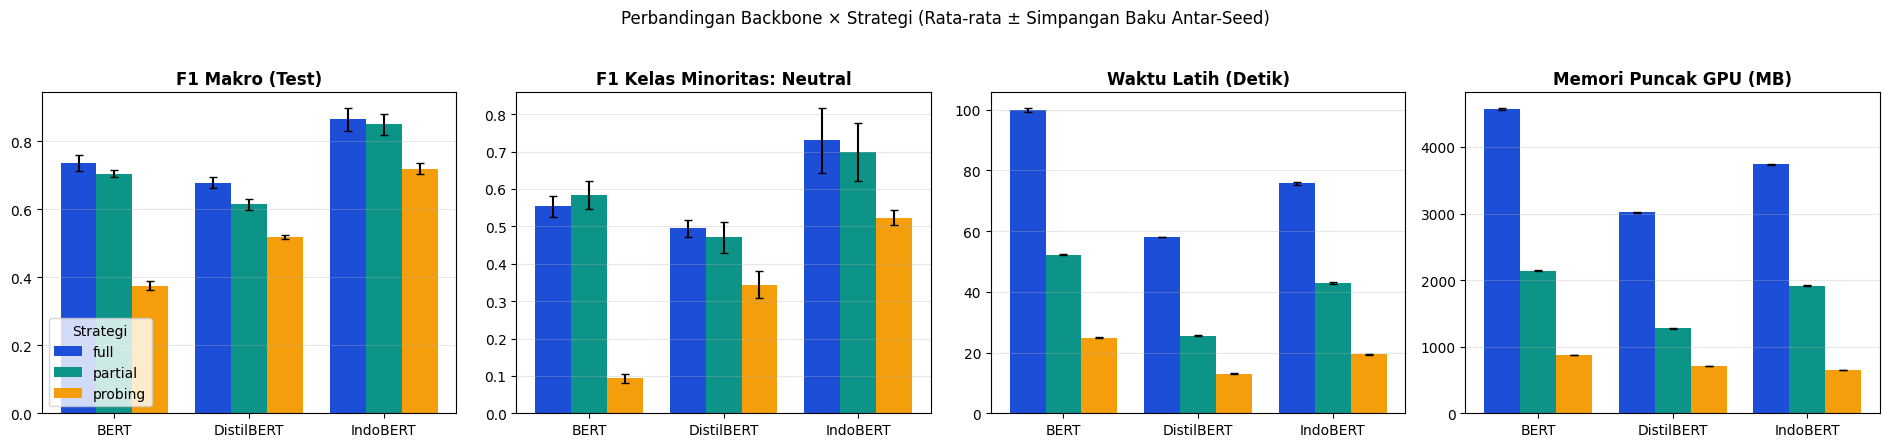

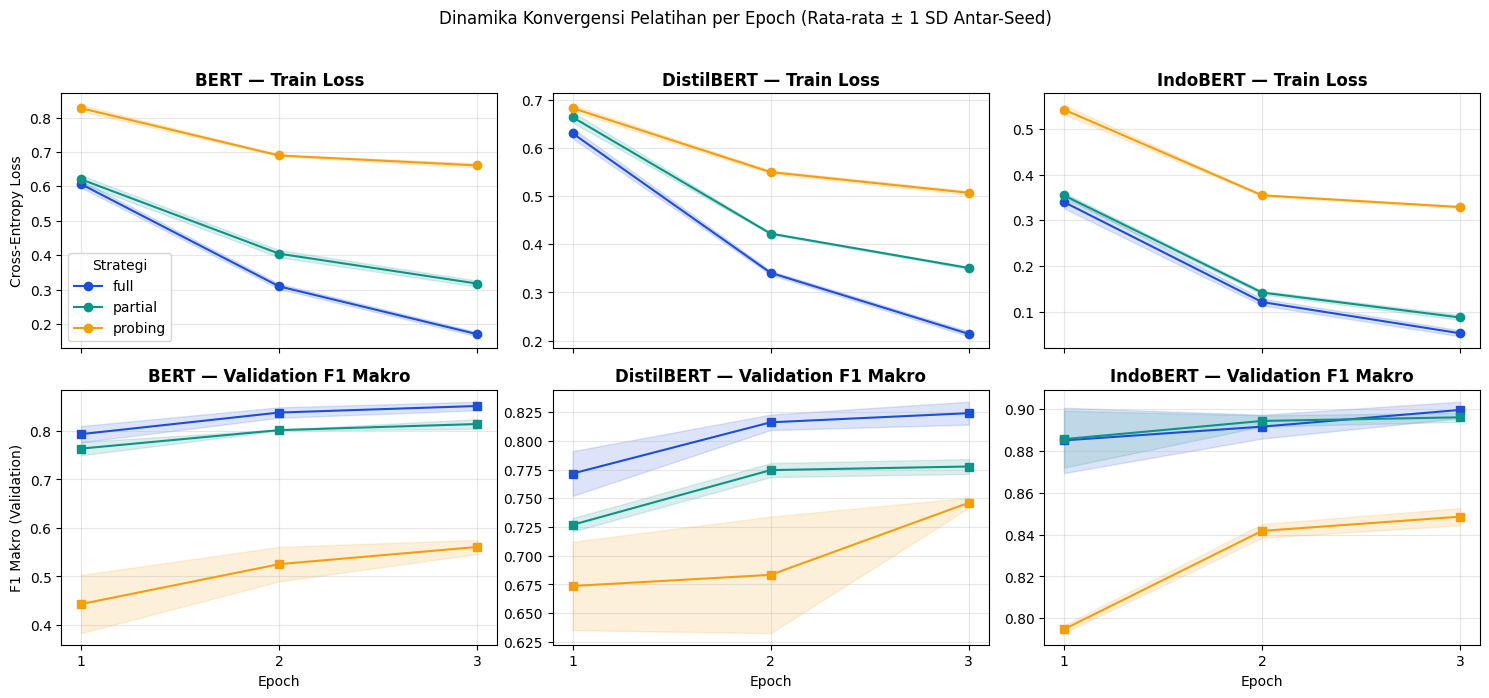

In [14]:
def grafik_perbandingan(rekap_df, df_raw):
    # 1. Grafik Batang Utama: F1 Makro, F1 Kelas Neutral, Waktu Latih, & Memori Puncak GPU
    fig, ax = plt.subplots(1, 4, figsize=(19, 4.3))
    panel = [
        ("test_f1", "F1 Makro (Test)"),
        ("test_f1_neu", "F1 Kelas Minoritas: Neutral"),
        ("waktu_latih_s", "Waktu Latih (Detik)"),
        ("mem_puncak_mb", "Memori Puncak GPU (MB)")
    ]
    lebar = 0.8 / len(STRATEGIES)
    x = np.arange(len(BACKBONES))
    warna = {"full": "#1d4ed8", "partial": "#0d9488", "probing": "#f59e0b"}

    for a, (k, judul_p) in zip(ax, panel):
        if f"{k}_mean" not in rekap_df.columns:
            continue
        for j, s in enumerate(STRATEGIES):
            sub = rekap_df[rekap_df["strategi"] == s].set_index("backbone").reindex(list(BACKBONES))
            a.bar(
                x + j * lebar - 0.4 + lebar / 2, sub[f"{k}_mean"], lebar,
                yerr=sub[f"{k}_std"].fillna(0), capsize=3, label=s, color=warna.get(s)
            )
        a.set_xticks(x)
        a.set_xticklabels(list(BACKBONES))
        a.set_title(judul_p, fontweight="bold")
        a.grid(axis="y", alpha=0.3)
    ax[0].legend(title="Strategi")
    fig.suptitle("Perbandingan Backbone × Strategi (Rata-rata ± Simpangan Baku Antar-Seed)", y=1.03, fontsize=12)
    plt.tight_layout()
    plt.show()

    # 2. Kurva Pelatihan Per Epoch (Training Loss & Validation F1)
    if "loss_per_epoch" in df_raw.columns and "val_f1_per_epoch" in df_raw.columns:
        fig, axes = plt.subplots(2, len(BACKBONES), figsize=(15, 6.8), sharex=True)
        if len(BACKBONES) == 1:
            axes = np.array(axes).reshape(2, 1)

        for col_idx, b in enumerate(BACKBONES):
            for s in STRATEGIES:
                sub = df_raw[(df_raw["backbone"] == b) & (df_raw["strategi"] == s)]
                if len(sub) == 0:
                    continue
                losses = np.array([[float(v) for v in str(x).split(";")] for x in sub["loss_per_epoch"]])
                val_f1s = np.array([[float(v) for v in str(x).split(";")] for x in sub["val_f1_per_epoch"]])
                epochs_x = np.arange(1, losses.shape[1] + 1)

                # Baris 0: Train Loss
                m_l, s_l = losses.mean(axis=0), (losses.std(axis=0, ddof=1) if len(losses) > 1 else np.zeros(losses.shape[1]))
                axes[0, col_idx].plot(epochs_x, m_l, marker="o", label=s, color=warna.get(s))
                axes[0, col_idx].fill_between(epochs_x, m_l - s_l, m_l + s_l, alpha=0.15, color=warna.get(s))

                # Baris 1: Validation F1
                m_f, s_f = val_f1s.mean(axis=0), (val_f1s.std(axis=0, ddof=1) if len(val_f1s) > 1 else np.zeros(val_f1s.shape[1]))
                axes[1, col_idx].plot(epochs_x, m_f, marker="s", label=s, color=warna.get(s))
                axes[1, col_idx].fill_between(epochs_x, m_f - s_f, m_f + s_f, alpha=0.15, color=warna.get(s))

            axes[0, col_idx].set_title(f"{b} — Train Loss", fontweight="bold")
            axes[1, col_idx].set_title(f"{b} — Validation F1 Makro", fontweight="bold")
            axes[1, col_idx].set_xlabel("Epoch")
            axes[0, col_idx].grid(True, alpha=0.3)
            axes[1, col_idx].grid(True, alpha=0.3)
            axes[1, col_idx].set_xticks(epochs_x)

        axes[0, 0].set_ylabel("Cross-Entropy Loss")
        axes[1, 0].set_ylabel("F1 Makro (Validation)")
        axes[0, 0].legend(title="Strategi")
        fig.suptitle("Dinamika Konvergensi Pelatihan per Epoch (Rata-rata ± 1 SD Antar-Seed)", y=1.02, fontsize=12)
        plt.tight_layout()
        plt.show()


grafik_perbandingan(rekap, df_hasil)

### Benchmark Inferensi Terkendali dalam Satu Sesi
Mengukur ulang ketiga backbone **secara bergantian** (`BERT → DistilBERT → IndoBERT`, diulang 5 kali) pada GPU dan sesi yang sama agar kondisi termal dan *clock rate* GPU adil bagi ketiganya. Kecepatan inferensi bergantung pada arsitektur (dan panjang urutan token), bukan pada strategi fine-tuning. Gunakan tabel ini sebagai rujukan utama latensi dan *throughput* inferensi.

In [15]:
def benchmark_inferensi(ulang=5):
    models, keys = {}, {}
    for nama in BACKBONES:
        if nama not in DATA:
            DATA[nama] = siapkan_data(nama)
        set_seed(CFG["seeds"][0])
        models[nama] = buat_model(nama).to(DEVICE).eval()
        keys[nama] = set(inspect.signature(models[nama].forward).parameters)

    waktu = {n: [] for n in models}
    for _ in range(ulang):
        for n, m in models.items():                  # bergantian per putaran agar kondisi termal GPU adil
            waktu[n].append(waktu_inferensi_ms(m, DATA[n]["val_batches"], keys[n], ulang=1))

    hasil = pd.DataFrame([{
        "Backbone": n,
        "Inferensi Median (ms/kal)": float(np.median(w)),
        "Inferensi Mean (ms/kal)": float(np.mean(w)),
        "Std (ms/kal)": float(np.std(w, ddof=1)) if len(w) > 1 else 0.0,
        "Throughput (kalimat/detik)": 1000.0 / float(np.median(w)),
        "Param Total": f"{hitung_param(models[n])[0]:,}",
        "Ulang": ulang,
        "Sesi": SESI,
        "GPU": GPU,
    } for n, w in waktu.items()])

    hasil.to_csv(FILE_BENCH, index=False)
    del models; gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return hasil


bench = benchmark_inferensi()
display(bench.round({
    "Inferensi Median (ms/kal)": 3,
    "Inferensi Mean (ms/kal)": 3,
    "Std (ms/kal)": 3,
    "Throughput (kalimat/detik)": 1
}))
print(f"Tersimpan: {os.path.basename(FILE_BENCH)} (sesi {SESI}, {GPU})")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,Backbone,Inferensi Median (ms/kal),Inferensi Mean (ms/kal),Std (ms/kal),Throughput (kalimat/detik),Param Total,Ulang,Sesi,GPU
0,BERT,1.480,1.478,0.004,675.8,"177,855,747",5,20261120-081311,Tesla T4
1,DistilBERT,0.742,0.742,0.003,1347.7,"135,326,979",5,20261120-081311,Tesla T4
2,IndoBERT,1.158,1.159,0.004,863.2,"124,443,651",5,20261120-081311,Tesla T4


Tersimpan: benchmark_inferensi_smsa_5579c1.csv (sesi 20261120-081311, Tesla T4)


## 6. Evaluasi Mendalam: Confusion Matrix, F1 Per Kelas, & Analisis Kesalahan (Error Analysis)
Sel ini memuat prediksi uji tersimpan (`.npz`) dari kombinasi terbaik menurut **F1 makro validasi** (bukan test, agar pemilihan tidak memakai data uji) untuk menampilkan:
1. **Laporan Klasifikasi Per Kelas** (`Precision`, `Recall`, `F1-Score` untuk `positive`, `neutral`, `negative`).
2. **Confusion Matrix** perbandingan antara model terbaik (*Full Fine-Tuning*) dan *Linear Probing* untuk melihat pola kesalahan pada kelas minoritas `neutral`.
3. **10 Contoh Kesalahan Prediksi Nyata** pada data uji untuk mengidentifikasi penyebab misklasifikasi (sarkasme, sentimen campuran, atau ambiguitas konteks).

=== LAPORAN KLASIFIKASI PER KELAS: IndoBERT (full, seed=42) ===
              precision    recall  f1-score   support

    positive     0.9083    0.9519    0.9296       208
     neutral     1.0000    0.6250    0.7692        88
    negative     0.8943    0.9951    0.9420       204

    accuracy                         0.9120       500
   macro avg     0.9342    0.8573    0.8803       500
weighted avg     0.9187    0.9120    0.9064       500



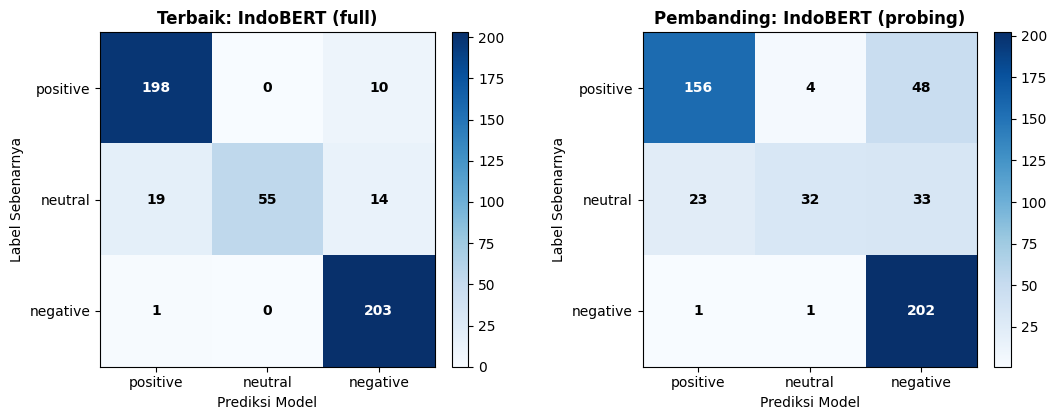


Total kesalahan prediksi pada test set (IndoBERT - full, seed=42): 44 dari 500 (8.8%)


,Teks Uji,Label Asli,Prediksi
0,"iya enak banget soal nya ; iya dong indomie mah teh terbaik . iya , lalu aku juga tidak suka orang yang padahal jelas-jelas dia salah dan harus nya minta maaf , tapi adem ayem saja sedangkan aku nya sudah menderita .",positive,negative
1,kalau driver go jek tidak pelayanan prima meminta bungkus acar untuk mengambil saos tambahan hilang nafsu makan saya . bravo driver go jek .,positive,negative
2,"karena shopee bukan barang shope , dia itu tempat belanjaan aku yang paling luar biasa ! pelayanan nya oke punya , disko nya banjir !",positive,negative
3,daftar harga dispenser 2018 terbaik yang ada di blibli.com memuat banyak produk . salah satu nya adalah miyako wdp - 200 dispenser . produk ini merupakan dispenser dengan penempatan galon di bawah sehingga anda tidak perlu mengangkat galon saat akan mengisi air .,neutral,positive
4,"kami bukan dalam kapasitas menentukan jangan / nyapres , mbk .",neutral,negative
5,"adab di media sosial itu jelas , kok . suka silakan like , mengikuti . tidak suka , unfoll / block , simpel . dan kita memiliki hak yang sama untuk melakukan nya .",neutral,positive
6,"kalau tidak suka gaperlu didukung mas , dukung saja yang menurut mas daus itu bisa bawa indonesia jauh lebih baik . yang penting kita harus menomorsatukan asas etika .",neutral,negative
7,ada tiga tahap . pertama harus unlock bootloader terus pasang twrp terus robot deh xiaomi kamu tipe berapa ya ? soal nya suka beda gitu loh,neutral,negative
8,"maaf ini oot . yang hape nya xiaomi , bisa bantu aku tidak . ini kalau aku lagi buka twit atau saya begitu suka menang . nah yang aku lingkarkan merah itu aplikasi yang menghilang begitu . ada yang tahu kenapa dan bagaimana cara menyembuhkan nya :",neutral,negative
9,di indonesia pilihan brand smartphone kan melimpah . kalau tidak suka cara xiaomi menjalankan bisnis nya ya tinggal pilih brand lain . dibawa santai saja .,neutral,positive


In [16]:
def analisis_kesalahan_dan_cm(rekap_df, df_raw):
    # Pilih kombinasi backbone x strategi terbaik berdasarkan rata-rata F1 makro VALIDASI (bukan test)
    kolom_pilih = "val_f1_mean" if "val_f1_mean" in rekap_df.columns else "test_f1_mean"
    idx_best = rekap_df[kolom_pilih].idxmax()
    best_b = rekap_df.loc[idx_best, "backbone"]
    best_s = rekap_df.loc[idx_best, "strategi"]

    # Ambil seed pertama yang tersedia untuk kombinasi terbaik dan untuk probing pada backbone yang sama
    sub_best = df_raw[(df_raw["backbone"] == best_b) & (df_raw["strategi"] == best_s)]
    seed_ref = int(sub_best["seed"].iloc[0])

    path_best = os.path.join(PRED_DIR, f"{best_b}_{best_s}_seed{seed_ref}.npz")
    if not os.path.exists(path_best):
        print(f"Berkas prediksi {path_best} tidak ditemukan. Lewati visualisasi Confusion Matrix.")
        return

    d_best = np.load(path_best)
    gold_b, pred_b = d_best["gold"], d_best["pred"]

    print(f"=== LAPORAN KLASIFIKASI PER KELAS: {best_b} ({best_s}, seed={seed_ref}) ===")
    print(classification_report(gold_b, pred_b, target_names=LABELS, digits=4, zero_division=0))

    # Plot Confusion Matrix (Best vs Probing pada backbone terbaik)
    path_prob = os.path.join(PRED_DIR, f"{best_b}_probing_seed{seed_ref}.npz")
    has_prob = os.path.exists(path_prob)

    fig, axes = plt.subplots(1, 2 if has_prob else 1, figsize=(11 if has_prob else 5.5, 4.3))
    if not has_prob:
        axes = [axes]

    kandidat = [(axes[0], gold_b, pred_b, f"Terbaik: {best_b} ({best_s})")]
    if has_prob:
        d_prob = np.load(path_prob)
        kandidat.append((axes[1], d_prob["gold"], d_prob["pred"], f"Pembanding: {best_b} (probing)"))

    for ax_i, g_arr, p_arr, title_i in kandidat:
        cm = confusion_matrix(g_arr, p_arr, labels=[0, 1, 2])
        im = ax_i.imshow(cm, cmap="Blues")
        ax_i.set_xticks(range(len(LABELS))); ax_i.set_xticklabels(LABELS)
        ax_i.set_yticks(range(len(LABELS))); ax_i.set_yticklabels(LABELS)
        ax_i.set_xlabel("Prediksi Model")
        ax_i.set_ylabel("Label Sebenarnya")
        ax_i.set_title(title_i, fontweight="bold")
        for r_idx in range(cm.shape[0]):
            for c_idx in range(cm.shape[1]):
                val = cm[r_idx, c_idx]
                ax_i.text(c_idx, r_idx, f"{val}", ha="center", va="center",
                          color="white" if val > cm.max() / 2 else "black", fontweight="bold")
        plt.colorbar(im, ax=ax_i, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

    # Tampilkan 10 contoh kesalahan prediksi pada model terbaik
    salah_idx = np.where(gold_b != pred_b)[0]
    print(f"\nTotal kesalahan prediksi pada test set ({best_b} - {best_s}, seed={seed_ref}): "
          f"{len(salah_idx)} dari {len(gold_b)} ({len(salah_idx)/len(gold_b):.1%})")
    if len(salah_idx) > 0:
        contoh_salah = pd.DataFrame({
            "Teks Uji": test_df.loc[salah_idx[:10], "text"].values,
            "Label Asli": [LABELS[i] for i in gold_b[salah_idx[:10]]],
            "Prediksi": [LABELS[i] for i in pred_b[salah_idx[:10]]],
        })
        with pd.option_context("display.max_colwidth", None):
            display(contoh_salah)


analisis_kesalahan_dan_cm(rekap, df_hasil)

## 7. Panduan Pembahasan Laporan (Analisis Soal 2 & Soal 3 + Pertanyaan Riset Wajib)

> Seluruh kesimpulan pada laporan/slide harus **diturunkan dari angka hasil run yang valid** pada tabel di atas, bukan ditulis lebih dulu. Bagian ini hanya kerangka pertanyaan yang perlu dijawab.

### A. Perbandingan Backbone (Soal 2 — protokol full fine-tuning)
1. **H1:** Bandingkan F1 makro `IndoBERT`, `BERT`, dan `DistilBERT` pada **Tabel Soal 2** (rata-rata ± SD). Apakah keunggulan (jika ada) melebihi simpangan baku antar-seed? Periksa juga F1 kelas minoritas `neutral`.
2. **H2:** Hitung penghematan parameter, waktu latih, dan latensi inferensi DistilBERT terhadap BERT (gunakan tabel Q1 dan benchmark inferensi sesi tunggal), lalu bandingkan penurunan F1 dengan batas toleransi **≤ 3 poin**.
3. **Tokenizer:** Kaitkan kosakata IndoBERT (±30,5 ribu token, urutan lebih pendek) dengan kecepatan latih dan inferensinya dibanding model multibahasa (±119,5 ribu token).

### B. Perbandingan Strategi (Soal 3 — full vs partial freezing vs linear probing)
1. **H3:** Gunakan **Tabel Soal 3** dan tabel Q2: seberapa jauh partial dan probing tertinggal (atau setara) dibanding full, dan apakah selisihnya bermakna terhadap SD antar-seed?
2. **Catatan arsitektur:** jumlah parameter terlatih pada linear probing berbeda antar backbone. Pada BERT/IndoBERT hanya `classifier` (2.307 parameter), sedangkan DistilBERT juga melatih `pre_classifier` (±0,59 juta parameter), sehingga perbandingan probing antar backbone perlu dibaca dengan hati-hati.
3. **Trade-off:** hitung penghematan waktu latih dan memori puncak GPU tiap strategi relatif terhadap full.

### C. Tiga Pertanyaan Riset Wajib (dijawab di slide dan laporan)
- **Q1 — Backbone dengan trade-off akurasi vs efisiensi terbaik:** jawab dengan **F1 makro ± SD, waktu latih, waktu inferensi, dan jumlah parameter** (tabel Q1).
- **Q2 — Apakah strategi hemat komputasi cukup kompetitif?** Bandingkan selisih skor dengan simpangan antar-seed dan tentukan apakah selisihnya bermakna (tabel Q2).
- **Q3 — Kombinasi yang direkomendasikan:** **tetapkan kriteria lebih dulu** (mis. F1 makro minimum, batas waktu latih, batas ms/kalimat), lalu kaitkan dengan anggaran komputasi, kecepatan inferensi terukur, dan keterjelasan; bandingkan juga dengan baseline TF-IDF (apakah Transformer sepadan biayanya?).

### D. Pemeriksaan Kewajaran & Pembanding
Rujuk tabel kewajaran (F1 > 0,97 curiga kebocoran; F1 ≈ 0,33 atau di bawah baseline TF-IDF berarti perlu diperiksa) dan baris baseline TF-IDF, tebakan acak, serta SD antar-seed.

### E. Keterbatasan Eksperimen
- Subset latih *stratified* 5.000 contoh dari 10.933 data bersih (sesuai batas 3.000–6.000) dan 3 seed (`42, 43, 44`) demi efisiensi waktu eksekusi.
- Seleksi epoch hanya dari 3 epoch dan tanpa penyetelan *hyperparameter* terpisah per backbone.
- Uji resmi hanya 500 kalimat dengan sebaran kelas yang berbeda dari data latih, sehingga selisih kecil antar model perlu dibaca hati-hati.
- Waktu latih dan inferensi bergantung pada spesifikasi GPU dalam satu sesi yang sama.
